# Código geral

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D 
import glob
import os
import joblib
from scipy.fft import fft, fftfreq
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

CAMINHO_ALINHADO = "../arquivos/logs/logs_sensor_vale/logs_ext/normal/*.csv" 
CAMINHO_ANOMALIA = "../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_1_2/*.csv"
# CAMINHO_ANOMALIA_ESPECIFICA = "../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_1_2/log_tcp_2026-02-06_16-51-59_192.168.1.116.csv"

FS = 100           
N_JANELA = 128
STEP = 32
EIXOS = ['accel_x', 'accel_y', 'accel_z'] 

np.random.seed(5)

## FFT e Clusterização

In [2]:
def transformacao_fourier_eixo(sinal, N, fs):
    # # remove DC/gravidade
    # sinal_detrended = sinal - np.mean(sinal)
    # # FFT
    # yf = fft(sinal_detrended)
    yf = fft(sinal)
    # magnitude normalizada
    amplitude = np.abs(yf[0:N//2]) * (2.0 / N)
    return amplitude

def processar_dataset_ml4qs(caminho_arquivo):
    try:
        df = pd.read_csv(caminho_arquivo)
        if not all(col in df.columns for col in EIXOS): return None, None, None
            
        assinaturas_freq = []
        indices_centro = []
        
        for i in range(0, len(df) - N_JANELA, STEP):
            janela = df.iloc[i : i + N_JANELA]
            features_janela = []
            
            # FFT de cada eixo
            for eixo in EIXOS:
                amps = transformacao_fourier_eixo(janela[eixo].values, N_JANELA, FS)
                features_janela.extend(amps)
            
            # media de cada eixo
            medias_espaciais = [np.mean(janela[e].values) for e in EIXOS]
            features_janela.extend(medias_espaciais)

            assinaturas_freq.append(features_janela)
            indices_centro.append(i + N_JANELA//2)
                
        return np.array(assinaturas_freq), indices_centro, df 
    except Exception as e:
        print(f"Erro em {caminho_arquivo}: {e}")
        return None, None, None

PCA:
Número de componentes ideal: 6 componentes
Variância explicada: 74.33%


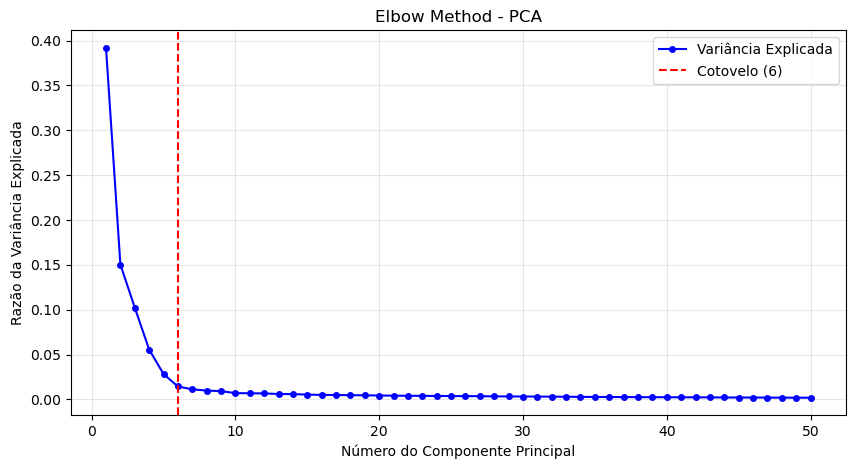

K-Means:
Número de clusters ideal: 3


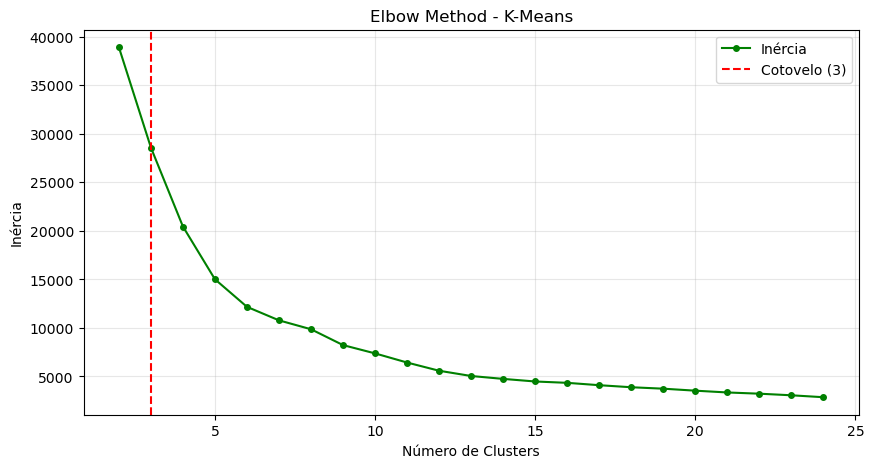

Limiar Distância: 14.1123
modelo salvo


In [3]:
# Função para encontrar o cotovelo usando o método Kneedle
# adaptada para aceitar o índice inicial (start_index: 1 pra PCA, 2 para K-Means)
def encontrar_cotovelo_kneedle(valores, start_index=1):
    n_pontos = len(valores)
    if n_pontos < 2: return start_index
    x_norm = np.linspace(0, 1, n_pontos)
    y_norm = (valores - np.min(valores)) / (np.max(valores) - np.min(valores))
    y_norm = 1 - y_norm 
    vec_reta = np.array([1, 1])
    vec_reta = vec_reta / np.linalg.norm(vec_reta)
    
    distancias = []
    for i in range(n_pontos):
        p = np.array([x_norm[i], y_norm[i]])
        proj = np.dot(p, vec_reta) * vec_reta
        dist = np.linalg.norm(p - proj)
        distancias.append(dist)
    return np.argmax(distancias) + start_index

todos_arquivos = sorted(glob.glob(CAMINHO_ALINHADO))
np.random.shuffle(todos_arquivos) # reprodutibilidade na ordem dos arquivos com a random seed

n_corte = int(len(todos_arquivos) * 0.8) # dividir em treino (80%) e teste (20%)
arquivos_treino = todos_arquivos[:n_corte]
arquivos_teste_normais = todos_arquivos[n_corte:]
X_bruto = []
for arq in arquivos_treino:
    feats, _, _ = processar_dataset_ml4qs(arq)
    if feats is not None: X_bruto.extend(feats)

X_bruto = np.array(X_bruto)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_bruto)

# PCA com elbow method
print("PCA:")

# ajustar PCA inicial com número alto de componentes para análise
n_components_test = min(50, X_scaled.shape[1])
pca_temp = PCA(n_components=n_components_test)
pca_temp.fit(X_scaled)

# calcula o num de componentes ideal pelo elbow method
explained_variance = pca_temp.explained_variance_ratio_
n_pca_ideal = encontrar_cotovelo_kneedle(explained_variance, start_index=1)

variancia_acumulada_ideal = np.sum(explained_variance[:n_pca_ideal])
print(f"Número de componentes ideal: {n_pca_ideal} componentes")
print(f"Variância explicada: {variancia_acumulada_ideal*100:.2f}%")

# plot do cotovelo PCA
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, 'bo-', markersize=4, label='Variância Explicada')
plt.axvline(x=n_pca_ideal, color='r', linestyle='--', label=f'Cotovelo ({n_pca_ideal})')
plt.title('Elbow Method - PCA')
plt.xlabel('Número do Componente Principal')
plt.ylabel('Razão da Variância Explicada')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# aplica PCA Definitivo
pca = PCA(n_components=n_pca_ideal)
X_pca = pca.fit_transform(X_scaled)

# Clusterização K-MEANS com elbow method
print("K-Means:")
inertias = []
silhouettes = []
k_range = range(2, 25) # Testar de 2 a 24 clusters possiveis

for k in k_range:
    kmeans_t = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_t.fit(X_pca)
    inertias.append(kmeans_t.inertia_)
    

# escolha do K Ideal com elbow method
# start_index=2 porque o range de K começa em 2
# melhor_k = encontrar_cotovelo_kneedle(inertias, start_index=2)
melhor_k = 3
print(f"Número de clusters ideal: {melhor_k}")

# plot do cotovelo K-Means
plt.figure(figsize=(10, 5))
plt.plot(k_range, inertias, 'go-', markersize=4, label='Inércia')
plt.axvline(x=melhor_k, color='r', linestyle='--', label=f'Cotovelo ({melhor_k})')
plt.title('Elbow Method - K-Means')
plt.xlabel('Número de Clusters')
plt.ylabel('Inércia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# treino final do K-means com o melhor K
kmeans = KMeans(n_clusters=melhor_k, random_state=42, n_init=10)
kmeans.fit(X_pca)

# cálculo do limiar_distancia:
distancias = kmeans.transform(X_pca)
# calcula distância de cada ponto ao centro do seu cluster
min_distancias = np.min(distancias, axis=1)
# limiar = percentil 99 das distâncias no treino
limiar_distancia = np.percentile(min_distancias, 99) 
print(f"Limiar Distância: {limiar_distancia:.4f}")

# Salvar modelo
pacote = {
    'scaler': scaler, 'pca': pca, 'kmeans': kmeans, 'limiar': limiar_distancia, 
    'fs': FS, 'n_janela': N_JANELA, 'step': STEP, 'eixos': EIXOS
}
joblib.dump(pacote, 'modelo_kmeans_final.pkl')
print("modelo salvo")

C:\Users\Raiza\AppData\Local\Temp\ipykernel_33448\3548884773.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('tab20', n_clusters) # Cores distintas


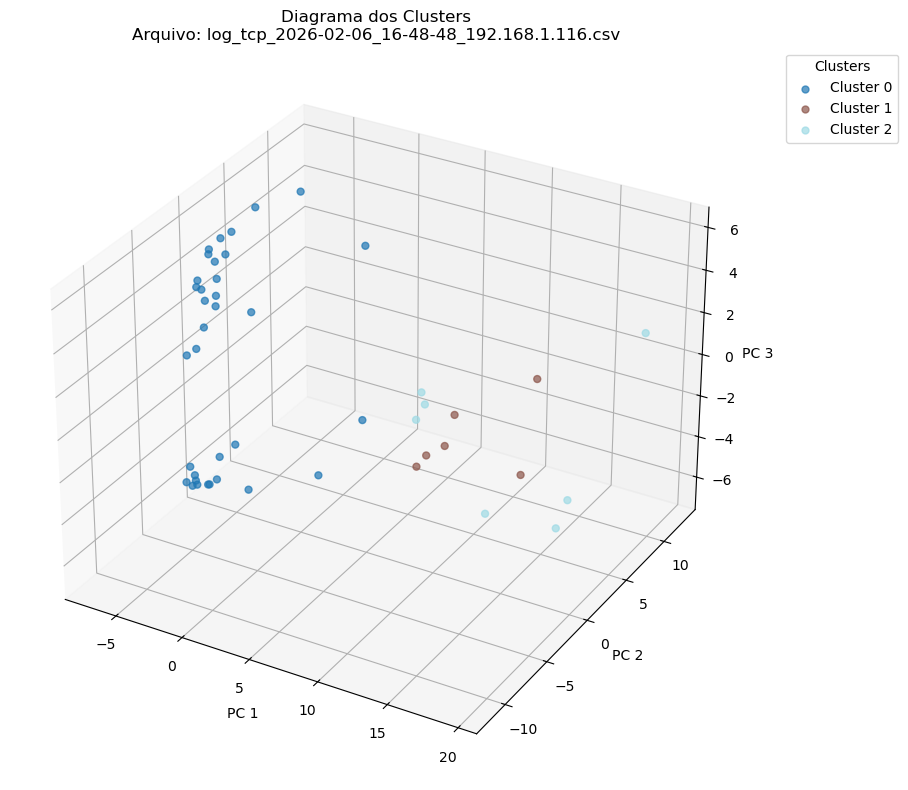

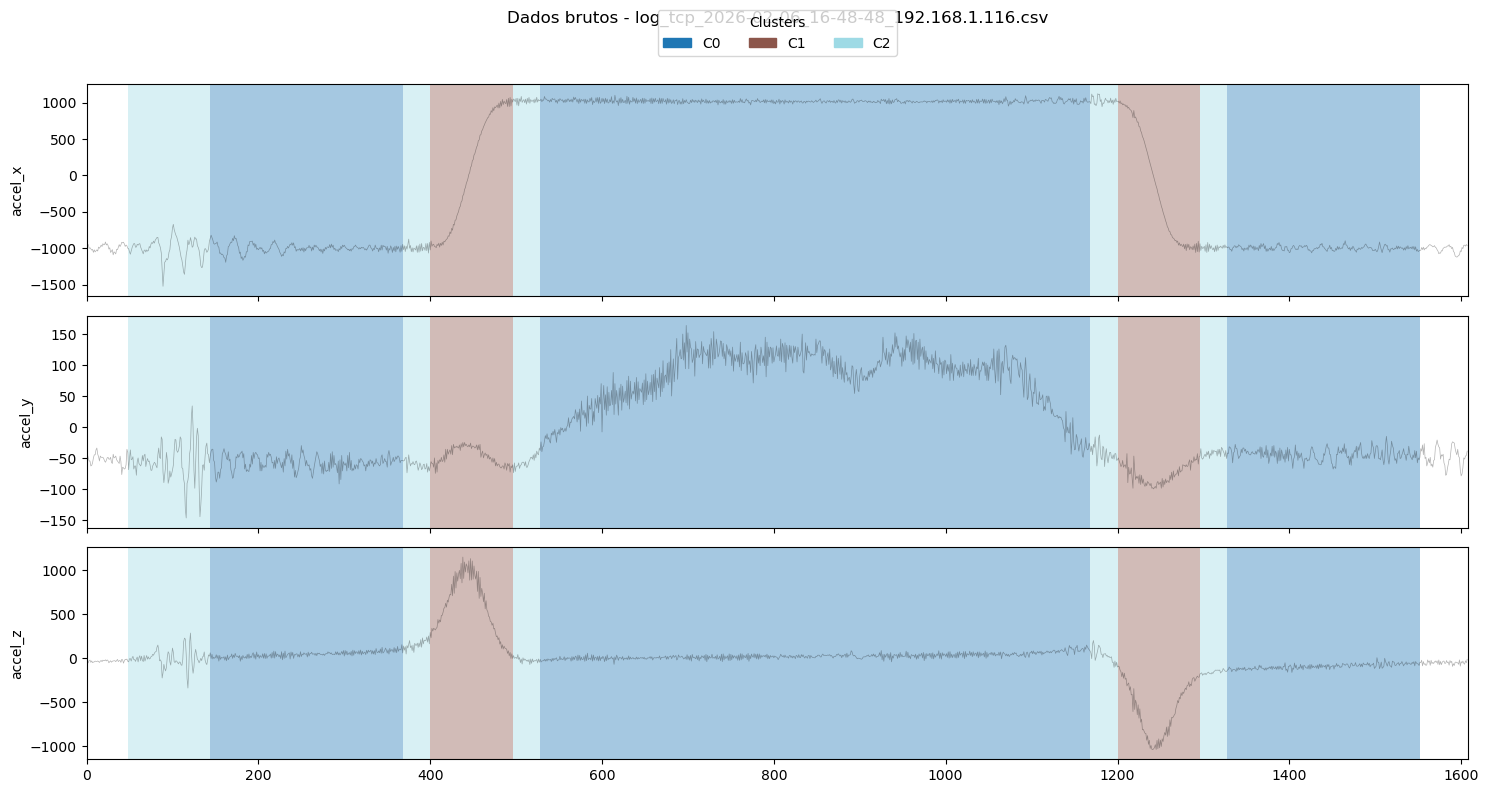

In [4]:
def visualizar_kmeans_clean(caminho_arquivo):
    feats, indices, df = processar_dataset_ml4qs(caminho_arquivo)
    if feats is None: return
    
    # Transformar
    feats_scaled = scaler.transform(feats)
    feats_pca = pca.transform(feats_scaled)
    labels = kmeans.predict(feats_pca)
    
    unique_labels = np.unique(labels)
    n_clusters = kmeans.n_clusters
    cmap = cm.get_cmap('tab20', n_clusters) # Cores distintas
    
    # Plot do diagrama 3D dos clusters
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    for lbl in unique_labels:
        mask = (labels == lbl)
        ax.scatter(feats_pca[mask, 0], feats_pca[mask, 1], feats_pca[mask, 2], 
                   color=cmap(lbl), s=25, alpha=0.7, label=f'Cluster {lbl}')
        
    ax.set_title(f"Diagrama dos Clusters\nArquivo: {os.path.basename(caminho_arquivo)}")
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.set_zlabel("PC 3")
    ax.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # Plot dos clusters sobre o sinal bruto para melhor visualização
    fig, axs = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
    cols = ['accel_x', 'accel_y', 'accel_z']
    
    for i, col in enumerate(cols):
        # Sinal
        sinal = df[col].values - np.mean(df[col].values)
        axs[i].plot(df.index, sinal, color='black', alpha=0.3, lw=0.5)
        axs[i].set_ylabel(col)
        
        # Colorir clusters
        for lbl in unique_labels:
            indices_cluster = np.where(labels == lbl)[0]
            if len(indices_cluster) == 0: continue
            cor = cmap(lbl)
            for idx in indices_cluster:
                c = indices[idx]
                axs[i].axvspan(c - STEP//2, c + STEP//2, color=cor, alpha=0.4, lw=0)
                
    patches = [plt.Rectangle((0,0),1,1, color=cmap(l), label=f'C{l}') for l in unique_labels]
    axs[0].legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, 1.1), 
                  ncol=min(len(unique_labels), 10), title="Clusters")
    
    axs[0].set_title(f"Dados brutos - {os.path.basename(caminho_arquivo)}", y=1.25)
    axs[2].set_xlim(0, len(df))
    plt.tight_layout()
    plt.show()

visualizar_kmeans_clean(arquivos_teste_normais[0])
if len(arquivos_teste_normais) <= 0:
    visualizar_kmeans_clean(arquivos_treino[0])

## Plot dos clusters no CAD

### Configurações

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from ezdxf import recover
from ezdxf.addons.drawing import Frontend, RenderContext
from ezdxf.addons.drawing.matplotlib import MatplotlibBackend
from ezdxf.math import Matrix44, Vec3
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
from plotly.subplots import make_subplots

In [6]:
try:
    doc, auditor = recover.readfile("../arquivos/esteira_ufmg_verlab-Sketch.dxf")
except IOError:
    print(f"Not a DXF file or a generic I/O error.")
except ezdxf.DXFStructureError:
    print(f"Invalid or corrupted DXF file.")

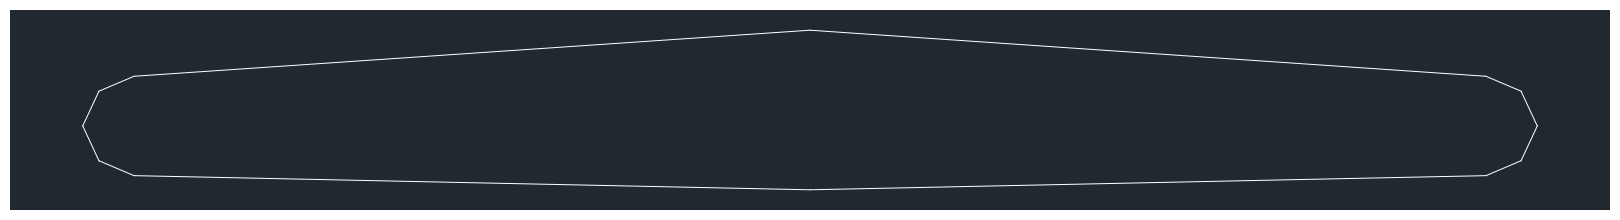

In [7]:
# The auditor.errors attribute stores severe errors, which may raise exceptions when rendering.
if not auditor.has_errors:
    fig = plt.figure()
    ax = fig.add_axes([0, 0, 1, 1])
    ctx = RenderContext(doc)
    out = MatplotlibBackend(ax)
    Frontend(ctx, out).draw_layout(doc.modelspace(), finalize=True)
    fig.savefig("your.png", dpi=300)

In [8]:
def circle_array(xc, yc, r, start, end):
    phi1 = start * np.pi / 180.0
    phi2 = end * np.pi / 180.0
    dphi = (phi2 - phi1) / np.ceil(200 * np.pi * r * (phi2 - phi1))  # 根据圆弧周长设置等间距
    array = np.arange(phi1, phi2, dphi)
    return xc + r * np.cos(array), yc + r * np.sin(array)


lines = []
circles = []
arcs = []
ellipses = []
splines = []
polylines = []

msp = doc.modelspace()
for entity in msp:
    transform = Matrix44()
    if entity.dxftype() == "LINE":
        start = transform.transform(entity.dxf.start)
        end = transform.transform(entity.dxf.end)
        lines.append((start, end))
    elif entity.dxftype() == "LWPOLYLINE":
        polyline = [transform.transform((p[0], p[1], 0)) for p in entity.get_points()]
        polylines.append(polyline)
    elif entity.dxftype() == "CIRCLE":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        circles.append((center, radius))
    elif entity.dxftype() == "ARC":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        start_angle = entity.dxf.start_angle
        end_angle = entity.dxf.end_angle
        arcs.append((center, radius, start_angle, end_angle))
    elif entity.dxftype() == "ELLIPSE":
        center = transform.transform(entity.dxf.center)
        major_axis_vec = Vec3(entity.dxf.major_axis)
        transformed_major_axis = transform.transform_direction(major_axis_vec)

        major_len = transformed_major_axis.magnitude
        angle_rad = math.atan2(transformed_major_axis.y, transformed_major_axis.x)
        rotation_deg = math.degrees(angle_rad)

        ratio = entity.dxf.ratio
        ellipses.append((center, major_len, ratio, rotation_deg))
    elif entity.dxftype() == "SPLINE":
        control_points = [transform.transform(p) for p in entity.control_points]
        fit_points = [transform.transform(p) for p in entity.fit_points]
        splines.append((control_points, fit_points))

print(f"lines:{len(lines)}")
print(f"circles:{len(circles)}")
print(f"arcs:{len(arcs)}")
print(f"ellipses:{len(ellipses)}")
print(f"splines:{len(splines)}")
print(f"polylines:{len(polylines)}")

lines:12
circles:0
arcs:0
ellipses:0
splines:0
polylines:0


In [9]:
all_raw_segments = []

# extrai segmentos de linhas sem a coordenada Z
for line in lines:
    p1 = (line[0][0], line[0][1])  # pt do inicio da linha
    p2 = (line[1][0], line[1][1])  # pt final da linha
    all_raw_segments.append((p1, p2))


# ordena uma lista de segmentos de linha pra formar um caminho continuo

def sort_segments(segments, tolerance=1e-5):
    if not segments:
        return []
    sorted_path = [segments.pop(0)]
    while segments:
        current_end_point = sorted_path[-1][1]
        found_next = False
        for i, segment in enumerate(segments):
            p_start, p_end = segment
            if np.linalg.norm(np.array(current_end_point) - np.array(p_start)) < tolerance:
                sorted_path.append(segments.pop(i))
                found_next = True
                break
            elif np.linalg.norm(np.array(current_end_point) - np.array(p_end)) < tolerance:
                # tinha linhas "invertidas" no cad, então inverte a ordem dos pontos
                sorted_path.append((p_end, p_start))
                segments.pop(i)
                found_next = True
                break
        if not found_next:
            print("Nem todos os segmentos foram conectados")
            break
    return sorted_path

sorted_segments = sort_segments(all_raw_segments)
pontos_do_contorno = [segment[0] for segment in sorted_segments]
pontos_do_contorno.append(sorted_segments[-1][1])
conveyor_path = np.array(pontos_do_contorno)
conveyor_path[:, 0] = conveyor_path[:, 0] * -1


In [10]:
def interpolate_path_by_distance(path_points, num_points):
    #calcula as distancias entre os pontos do cad
    segment_lengths = np.sqrt(np.sum(np.diff(path_points, axis=0)**2, axis=1))
    
    # calcula a distancia cumulativa em cada vertice original 
    cumulative_distances = np.zeros(len(path_points))
    cumulative_distances[1:] = np.cumsum(segment_lengths)
    
    total_length = cumulative_distances[-1]
    
    # cria os len(df_ref) pontos de distancia equidistante
    target_distances = np.linspace(0, total_length, num_points)
    
    # interpola as coordenadas usando as distancias cumulativas como o "eixo x" da interpolação.
    interp_x = np.interp(target_distances, cumulative_distances, path_points[:, 0])
    interp_y = np.interp(target_distances, cumulative_distances, path_points[:, 1])
    
    interpolated_points = np.vstack((interp_x, interp_y)).T
    
    # retorna o caminho E as distâncias cumulativas
    return interpolated_points, cumulative_distances

### Plots

In [11]:
offset = -15

# processar o arquivo e obter os clusters
arquivo_para_cad = arquivos_teste_normais[0]
feats, indices, df_base_alinhado = processar_dataset_ml4qs(arquivo_para_cad)
feats_pca = pca.transform(scaler.transform(feats))
labels_clusters = kmeans.predict(feats_pca)

hover_texts_brutos = []
for i, idx_centro in enumerate(indices):
    row = df_base_alinhado.iloc[idx_centro]
    text = (f"<b>Janela Orig:</b> {i}<br>" +
            f"<b>Cluster:</b> {labels_clusters[i]}<br>" +
            f"<b>Z:</b> {row['accel_z']:.2f}")
    hover_texts_brutos.append(text)
labels_com_offset = np.roll(labels_clusters, offset)
hover_com_offset = np.roll(hover_texts_brutos, offset)

# interpolar o cad para o número de janelas
interpolated_points_ref, _ = interpolate_path_by_distance(conveyor_path, len(labels_clusters))

fig = go.Figure()
# estrutura da esteira
fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], 
    mode='lines', line=dict(color='black', width=2), name='Esteira'
))

# clusters
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1],
    mode='markers',
    marker=dict(
        size=8, 
        color=labels_com_offset, 
        colorscale='Viridis', 
        showscale=True,
        colorbar=dict(
            tickvals=[0, 1, 2],
            ticktext=['Cluster 2', 'Cluster 1', 'Cluster 0'] )
        ),
    hoverinfo='text', 
    hovertext=hover_com_offset, 
    name='Dados (com Offset)'
))

fig.update_layout(
    title=f"Clusters no CAD",
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    width=1000, height=700, template="plotly_white"
)

print(f"arquivo: {os.path.basename(arquivo_para_cad)}")
fig.show()

arquivo: log_tcp_2026-02-06_16-48-48_192.168.1.116.csv


c:\Users\Raiza\anaconda3\Lib\site-packages\kaleido\_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




## Detecção de anomalia por distância até o centroide do cluster

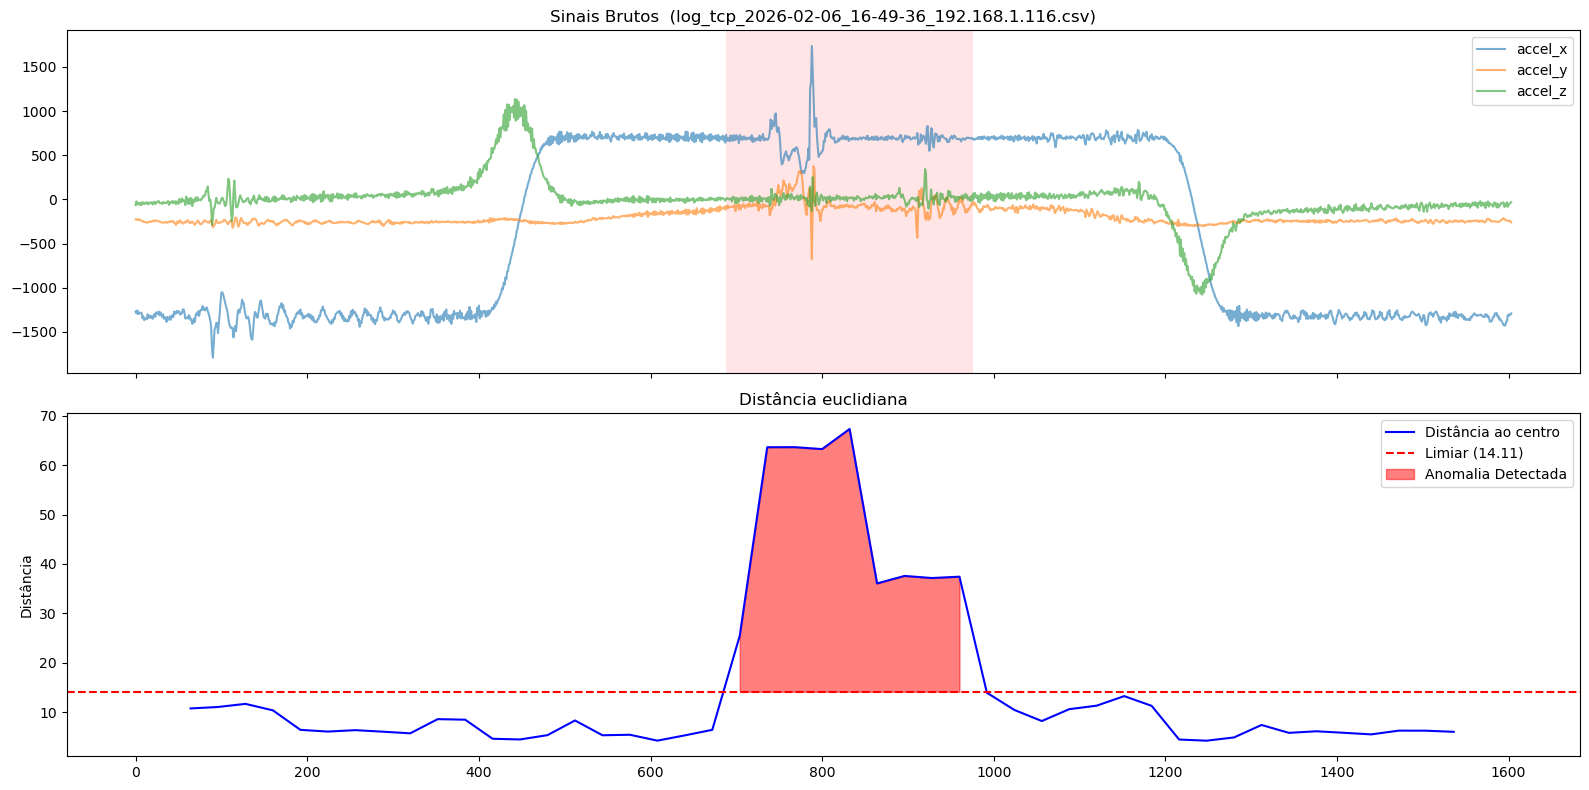

In [12]:
def diagnostico_anomalia_kmeans(caminho_arquivo):
    feats, indices, df = processar_dataset_ml4qs(caminho_arquivo)
    if feats is None: return
    feats_pca = pca.transform(scaler.transform(feats))
    
    # Calcular distância para o cluster atribuído
    distancias_todos = kmeans.transform(feats_pca)
    distancia_minima = np.min(distancias_todos, axis=1) # Distância pro seu centro
    is_anomaly = distancia_minima > limiar_distancia
    
    # PLOTS
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
    
    # Sinal bruto
    for col in EIXOS:
        ax1.plot(df.index, df[col], label=col, alpha=0.6)
    ax1.set_title(f"Sinais Brutos  ({os.path.basename(caminho_arquivo)})")
    ax1.legend(loc='upper right')
    
    # destacar anomalia
    for k, anomalo in enumerate(is_anomaly):
        if anomalo:
            c = indices[k]
            ax1.axvspan(c-STEP//2, c+STEP//2, color='red', alpha=0.1, lw=0)

    # Distância (anomalia)
    ax2.plot(indices, distancia_minima, color='blue', label='Distância ao centro')
    ax2.axhline(limiar_distancia, color='red', linestyle='--', label=f'Limiar ({limiar_distancia:.2f})')
    ax2.fill_between(indices, distancia_minima, limiar_distancia,  # Pinta área acima do limiar
                     where=(distancia_minima > limiar_distancia), 
                     color='red', alpha=0.5, label='Anomalia Detectada')
    ax2.set_title("Distância euclidiana")
    ax2.set_ylabel("Distância")
    ax2.legend()
    plt.tight_layout()
    plt.show()

lista = glob.glob(CAMINHO_ANOMALIA)
if lista:
    diagnostico_anomalia_kmeans(lista[0])
else:
    print("Sem arquivos de anomalia")

## Detecção de anomalia por cluster de anomalia

In [13]:
# CAMINHO_ANOMALIA = "../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/an_manual_entre_roletes_1_2/*.csv"
K_ANOMALIA = 4 
arquivos_anomalia = sorted(glob.glob(CAMINHO_ANOMALIA))

# 7 p treino, 2 p teste
arquivos_treino_an = arquivos_anomalia[:7]
arquivos_teste_an = arquivos_anomalia[7:]
print(f"conj de treino: {len(arquivos_treino_an)}")
print(f"conj de teste: {len(arquivos_teste_an)}")

def treinar_modelo_assinatura(lista_arquivos):
    todas_feats = []
    for arq in lista_arquivos:
        f, _, _ = processar_dataset_ml4qs(arq)
        if f is not None:
            todas_feats.append(f)
    X_an_treino = np.vstack(todas_feats)
    # aplicar PCA e treinar o K-Means de 4 clusters nos dados de anomalia
    X_an_pca = pca.transform(scaler.transform(X_an_treino))
    km_an = KMeans(n_clusters=4, random_state=42, n_init=10)
    km_an.fit(X_an_pca)
    return km_an
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_treino_an)

conj de treino: 7
conj de teste: 4


log_tcp_2026-02-06_16-49-36_192.168.1.116.csv


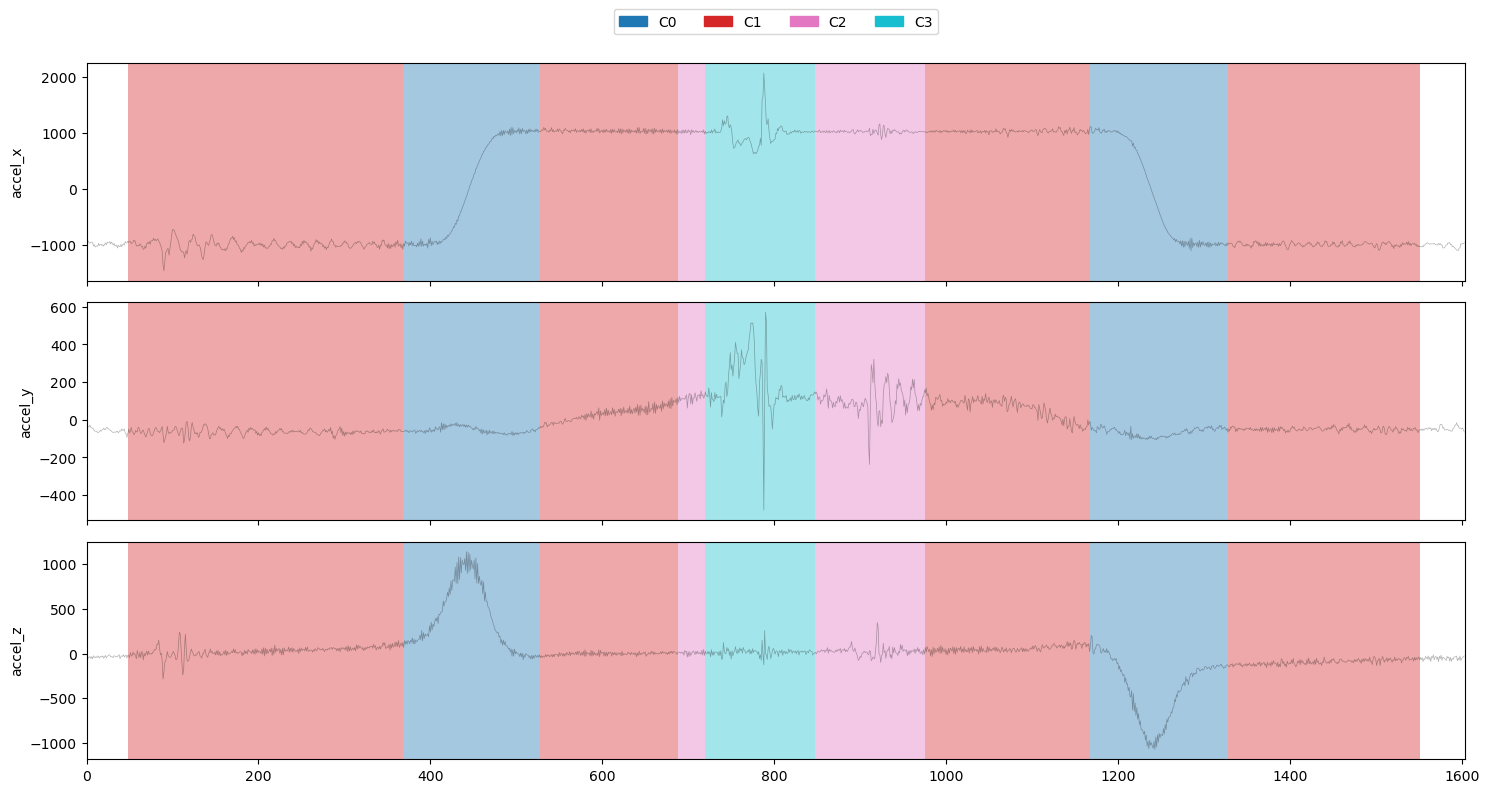

In [14]:
def visualizar_assinatura_anomalia(caminho_arquivo, kmeans_model):
    feats, indices, df = processar_dataset_ml4qs(caminho_arquivo)
    if feats is None: return

    feats_pca = pca.transform(scaler.transform(feats))
    labels = kmeans_model.predict(feats_pca)
    unique_labels = np.unique(labels)
    cmap = plt.get_cmap('tab10', K_ANOMALIA)

    fig, axs = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
    cols = ['accel_x', 'accel_y', 'accel_z']
    for i, col in enumerate(cols):
        sinal = df[col].values - np.mean(df[col].values)
        axs[i].plot(df.index, sinal, color='black', alpha=0.3, lw=0.5)
        axs[i].set_ylabel(col)
        
        for lbl in unique_labels:
            indices_cluster = np.where(labels == lbl)[0]
            if len(indices_cluster) == 0: continue
            cor = cmap(lbl)
            for idx in indices_cluster:
                c = indices[idx]
                axs[i].axvspan(c - STEP//2, c + STEP//2, color=cor, alpha=0.4, lw=0)          
    patches = [plt.Rectangle((0,0),1,1, color=cmap(l), label=f'C{l}') for l in range(K_ANOMALIA)] # (for l in unique_labels)
    axs[0].legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, 1.1), 
                  ncol=K_ANOMALIA)
    axs[2].set_xlim(0, len(df))
    plt.tight_layout()
    print(f"{os.path.basename(caminho_arquivo)}")
    plt.show()

# arquivo_exemplo = glob.glob(CAMINHO_AN_ESPECIFICA)[0]
# visualizar_assinatura_anomalia(arquivo_exemplo, kmeans_an_especifico)
visualizar_assinatura_anomalia(arquivos_treino_an[0], kmeans_an_especifico)

In [15]:
def identificar_ids_anomalos(kmeans_orig, kmeans_an):
    # centros dos dois modelos
    centros_normais = kmeans_orig.cluster_centers_
    centros_novos = kmeans_an.cluster_centers_
    ids_anomalos = []
    
    for i, centro_novo in enumerate(centros_novos):
        # calcula a distância desse novo centro para todos os centros normais,
        # se centro tá mais longe do normal do que seu limiar, é cluster de anomalia
        distancias = np.linalg.norm(centros_normais - centro_novo, axis=1)
        dist_minima = np.min(distancias)
        if dist_minima > limiar_distancia:
            ids_anomalos.append(i)
    return ids_anomalos

meus_ids_anomalia = identificar_ids_anomalos(kmeans, kmeans_an_especifico) # descobre os ids automaticamente
print(f"clusters identificados como anomalia: {meus_ids_anomalia}")
def testar_deteccao_automatica(lista_testes, kmeans_orig, kmeans_an, ids_an):
    for arq in lista_testes:
        print(f"\nArquivo: {os.path.basename(arq)}")
        feats, _, _ = processar_dataset_ml4qs(arq)
        if feats is None: continue
        f_pca = pca.transform(scaler.transform(feats))
        # distância do centro (análise 1)
        dists_normais = kmeans_orig.transform(f_pca)
        esta_longe = np.min(dists_normais, axis=1) > limiar_distancia
        # pertence a cluster de anomalia (análise 2)
        labels_an = kmeans_an.predict(f_pca)
        eh_assinatura = np.isin(labels_an, ids_an)
        confirmado = esta_longe & eh_assinatura
        
        print(f"distrib. de clusters: {dict(zip(*np.unique(labels_an, return_counts=True)))}")
        print(f"janelas com assinatura da anomalia: {np.sum(eh_assinatura)}")
        print(f"anomalia (longe do cluster normal e em um cluster de anomalia): {np.sum(confirmado)}")

testar_deteccao_automatica(arquivos_teste_an, kmeans, kmeans_an_especifico, meus_ids_anomalia)

clusters identificados como anomalia: [2, 3]

Arquivo: log_tcp_2026-02-06_16-51-27_192.168.1.116.csv
distrib. de clusters: {0: 10, 1: 32, 2: 4}
janelas com assinatura da anomalia: 4
anomalia (longe do cluster normal e em um cluster de anomalia): 4

Arquivo: log_tcp_2026-02-06_16-51-43_192.168.1.116.csv
distrib. de clusters: {0: 9, 1: 32, 2: 5}
janelas com assinatura da anomalia: 5
anomalia (longe do cluster normal e em um cluster de anomalia): 5

Arquivo: log_tcp_2026-02-06_16-51-59_192.168.1.116.csv
distrib. de clusters: {0: 10, 1: 31, 2: 5}
janelas com assinatura da anomalia: 5
anomalia (longe do cluster normal e em um cluster de anomalia): 5

Arquivo: log_tcp_2026-02-06_16-52-17_192.168.1.116.csv
distrib. de clusters: {0: 9, 1: 31, 2: 6}
janelas com assinatura da anomalia: 6
anomalia (longe do cluster normal e em um cluster de anomalia): 6


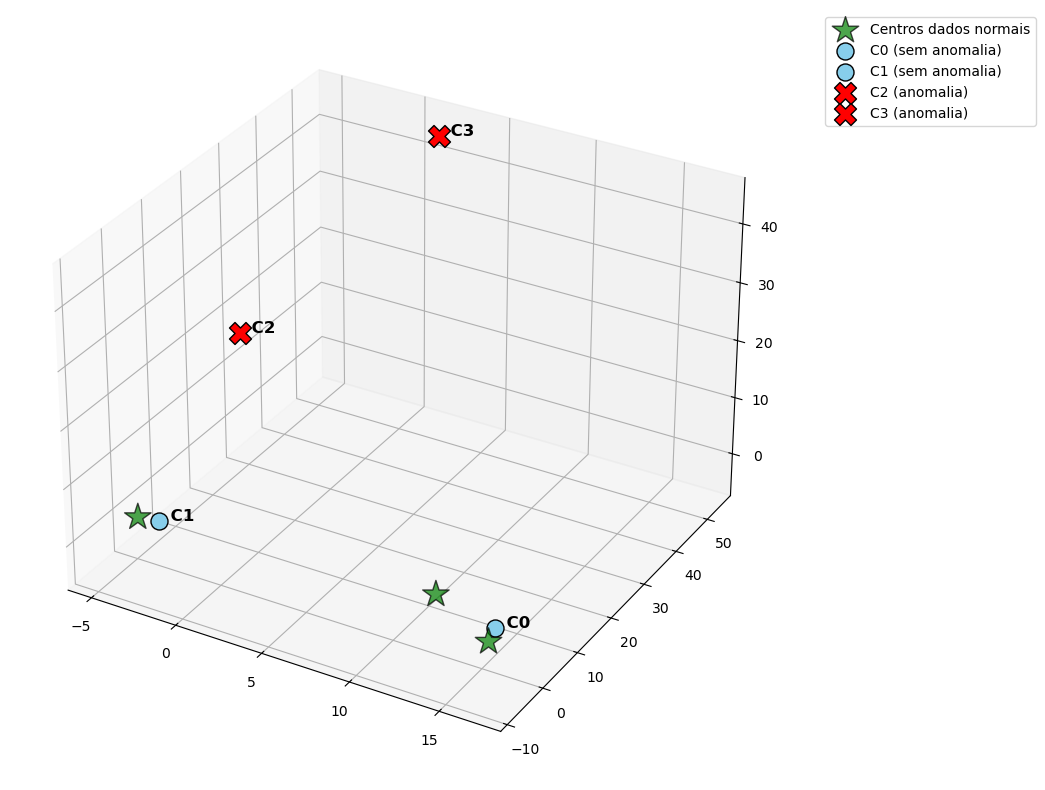

In [16]:
def visualizar_posicao_centroides(kmeans_orig, kmeans_an, ids_anomalos):
    centros_normais = kmeans_orig.cluster_centers_
    centros_anomalia = kmeans_an.cluster_centers_
    
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # centroides do modelo original de 3 clusters (estrelas verdes grandes)
    ax.scatter(centros_normais[:, 0], centros_normais[:, 1], centros_normais[:, 2], 
               s=400, c='green', marker='*', label='Centros dados normais', edgecolors='black', alpha=0.7)
    
    # centroides do modelo de anomalia
    for i, centro in enumerate(centros_anomalia):
        # Se id identificado como anomalo pela distancia, vermelho
        if i in ids_anomalos:
            cor = 'red'
            label_text = f'C{i} (anomalia)'
            marker = 'X'
            s = 250
        else:
            cor = 'skyblue'
            label_text = f'C{i} (sem anomalia)'
            marker = 'o'
            s = 150
            
        ax.scatter(centro[0], centro[1], centro[2], 
                   s=s, c=cor, marker=marker, label=label_text, edgecolors='black')
        ax.text(centro[0], centro[1], centro[2], f'  C{i}', size=12, weight='bold')
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', bbox_to_anchor=(1.05, 1))
    
    plt.tight_layout()
    plt.show()
visualizar_posicao_centroides(kmeans, kmeans_an_especifico, meus_ids_anomalia)

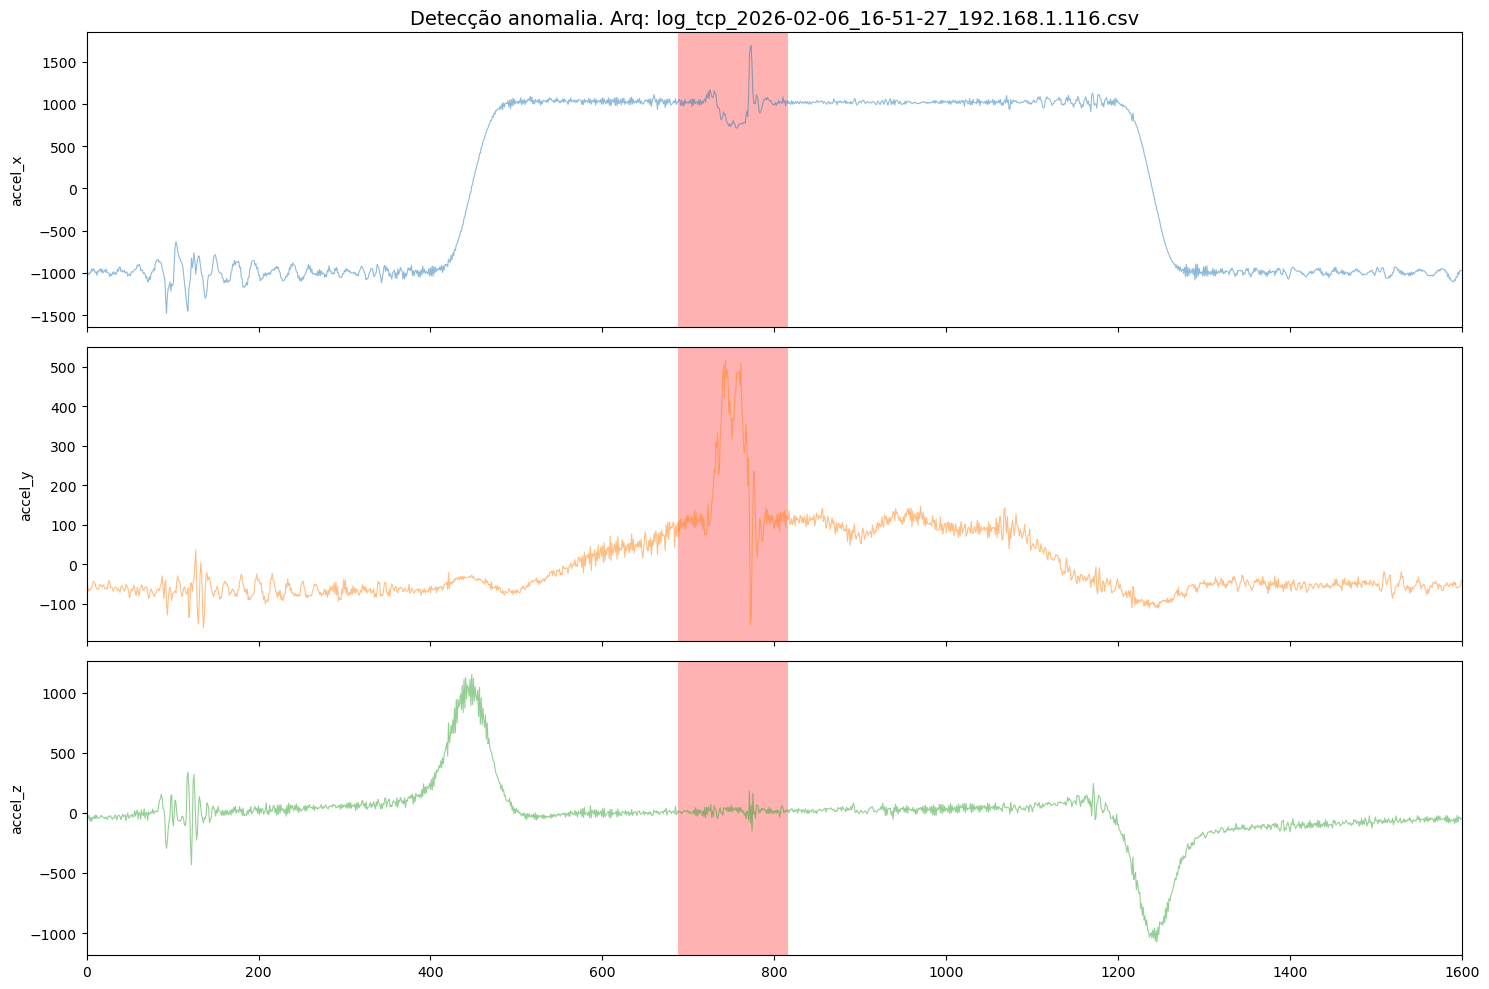

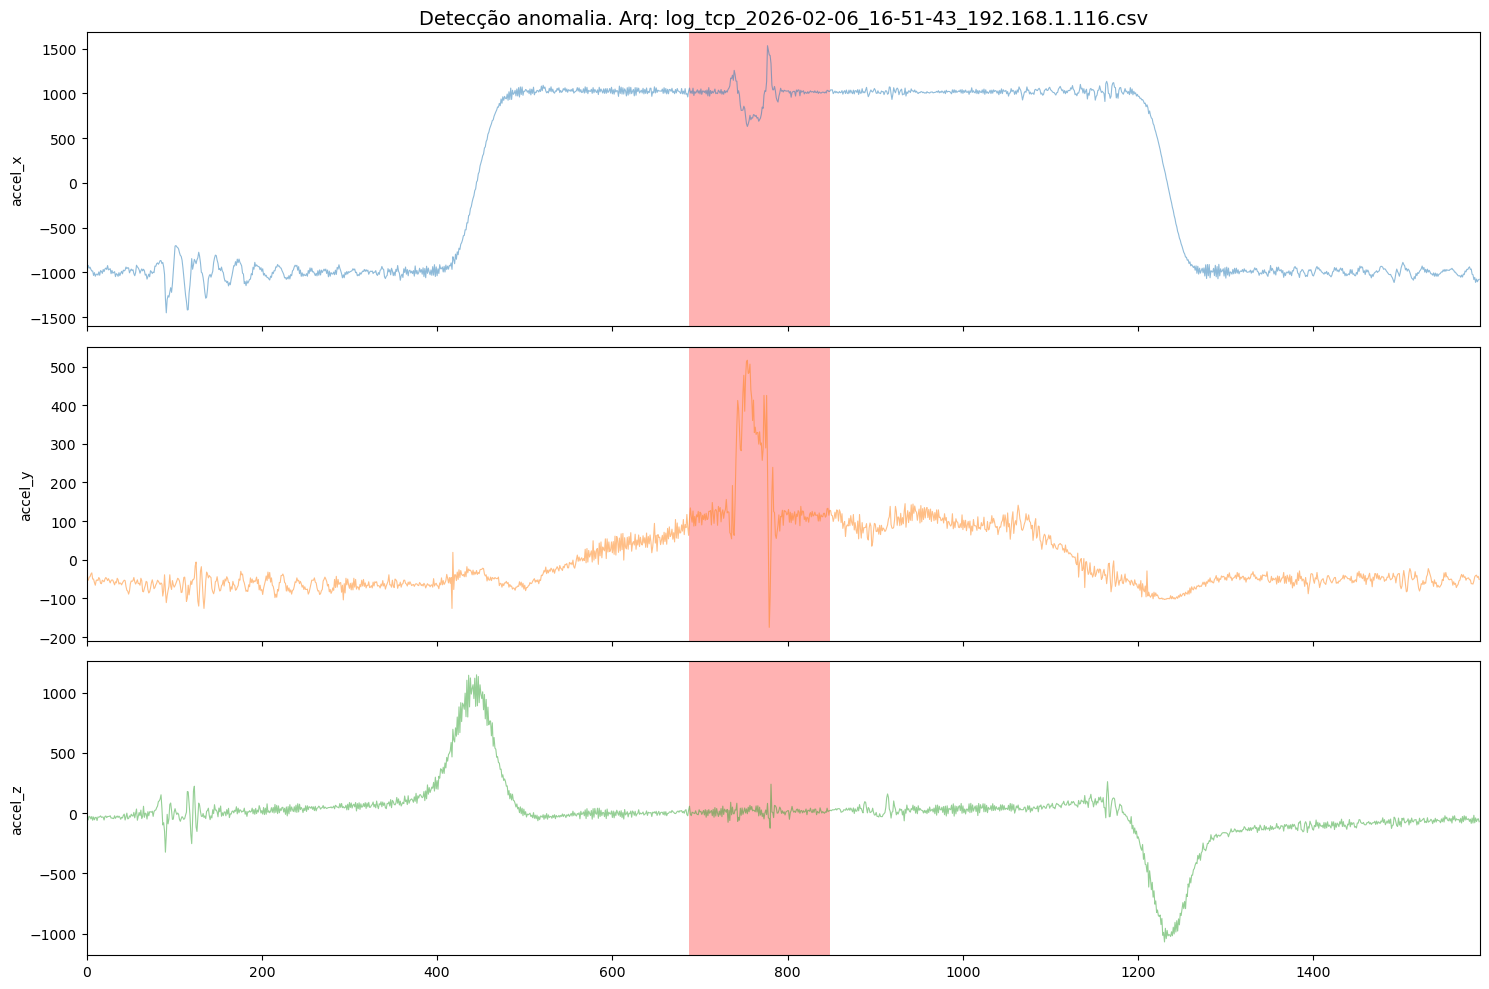

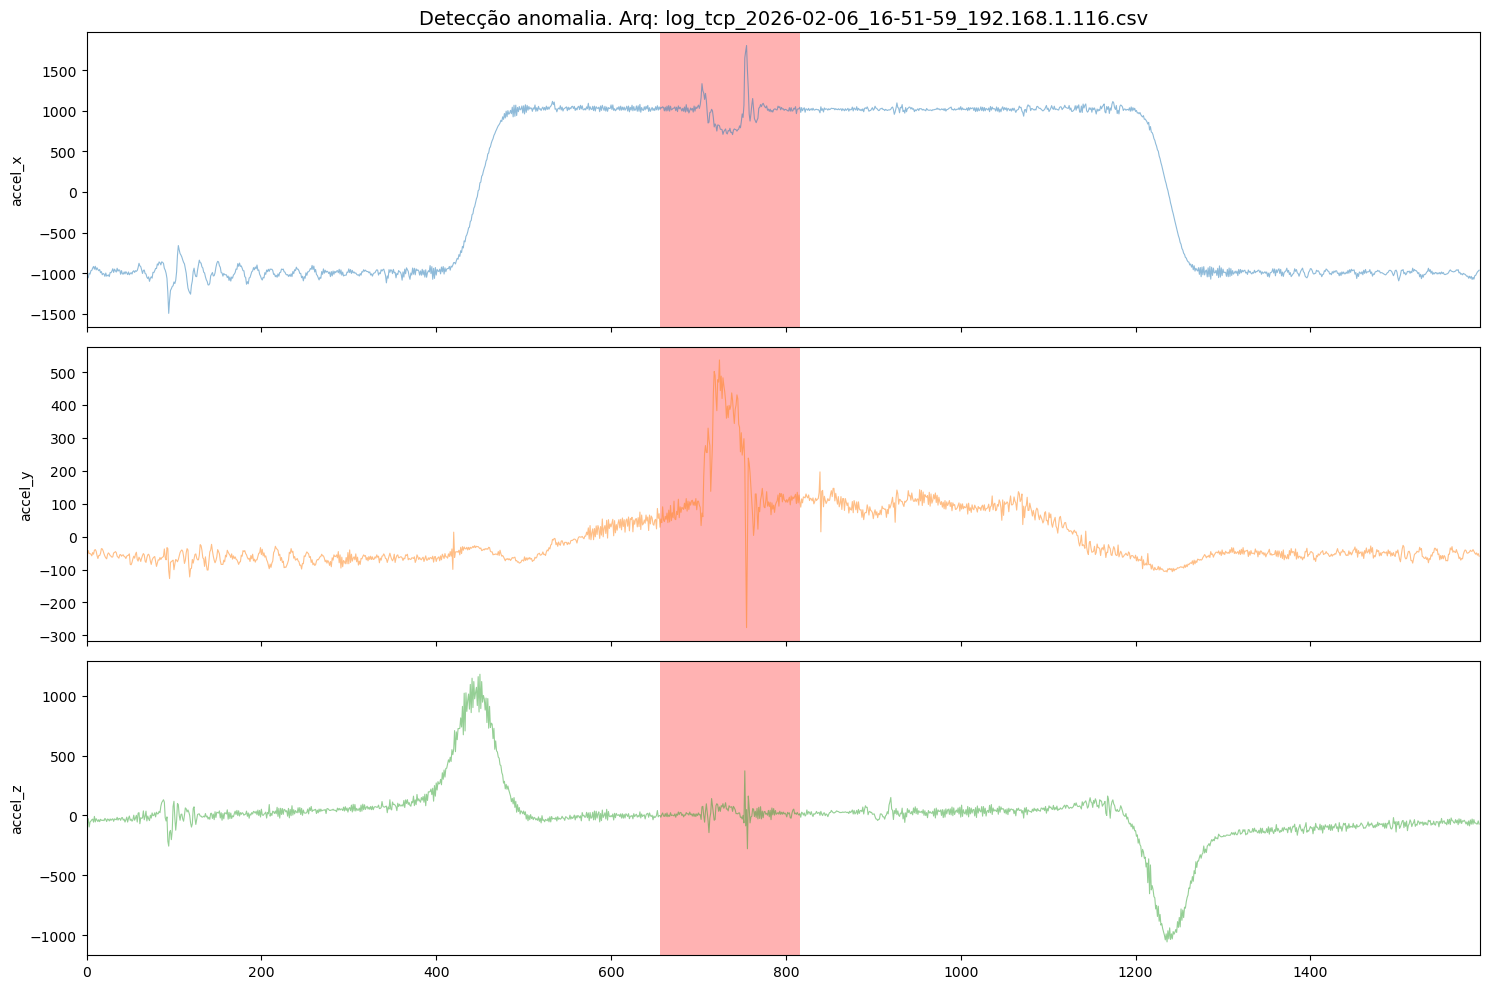

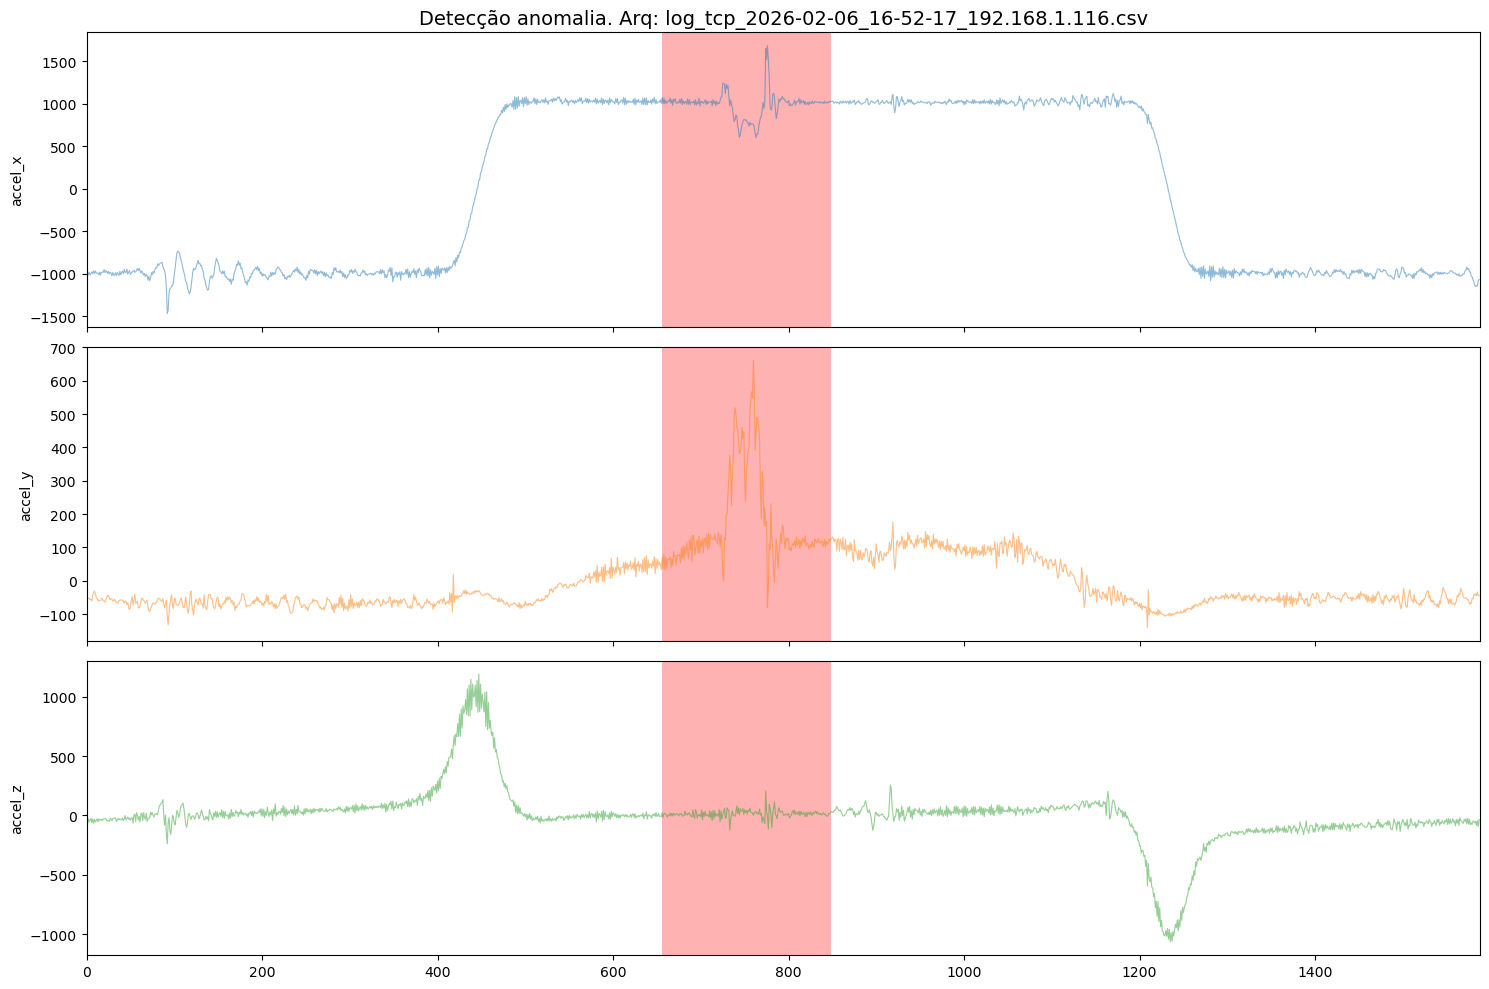

In [17]:
def visualizar_deteccao_confirmada(caminho_arquivo, kmeans_orig, kmeans_an, ids_an):
    # processar o arquivo e projetar no PCA
    feats, indices, df = processar_dataset_ml4qs(caminho_arquivo)
    if feats is None: return
    f_pca = pca.transform(scaler.transform(feats))

    # distância do cluster normal
    dists_normais = kmeans_orig.transform(f_pca)
    esta_longe = np.min(dists_normais, axis=1) > limiar_distancia
    # assinatura de anomalia
    labels_an = kmeans_an.predict(f_pca)
    eh_assinatura = np.isin(labels_an, ids_an)
    # interseção das duas condições
    confirmado = esta_longe & eh_assinatura
    indices_confirmados = np.where(confirmado)[0]
    
    fig, axs = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
    cols = ['accel_x', 'accel_y', 'accel_z']
    cores_eixos = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    for i, col in enumerate(cols):
        # sinal bruto
        sinal = df[col].values - np.mean(df[col].values)
        axs[i].plot(df.index, sinal, color=cores_eixos[i], alpha=0.5, lw=0.8)
        axs[i].set_ylabel(f"{col}")
        
        # janelas confirmadas
        primeiro_span = True
        for idx in indices_confirmados:
            centro_janela = indices[idx]
            axs[i].axvspan(centro_janela - STEP//2, centro_janela + STEP//2, 
                           color='red', alpha=0.3, lw=0)
            primeiro_span = False
    axs[0].set_title(f"Detecção anomalia. Arq: {os.path.basename(caminho_arquivo)}", fontsize=14)
    axs[2].set_xlim(0, len(df))
    
    plt.tight_layout()
    plt.show()

for arq in arquivos_teste_an:
    visualizar_deteccao_confirmada(arq, kmeans, kmeans_an_especifico, meus_ids_anomalia)

# Detecção e plots de todas as coletas de anomalia

## Anomalia extremidade direita

### Distância até centróide do cluster

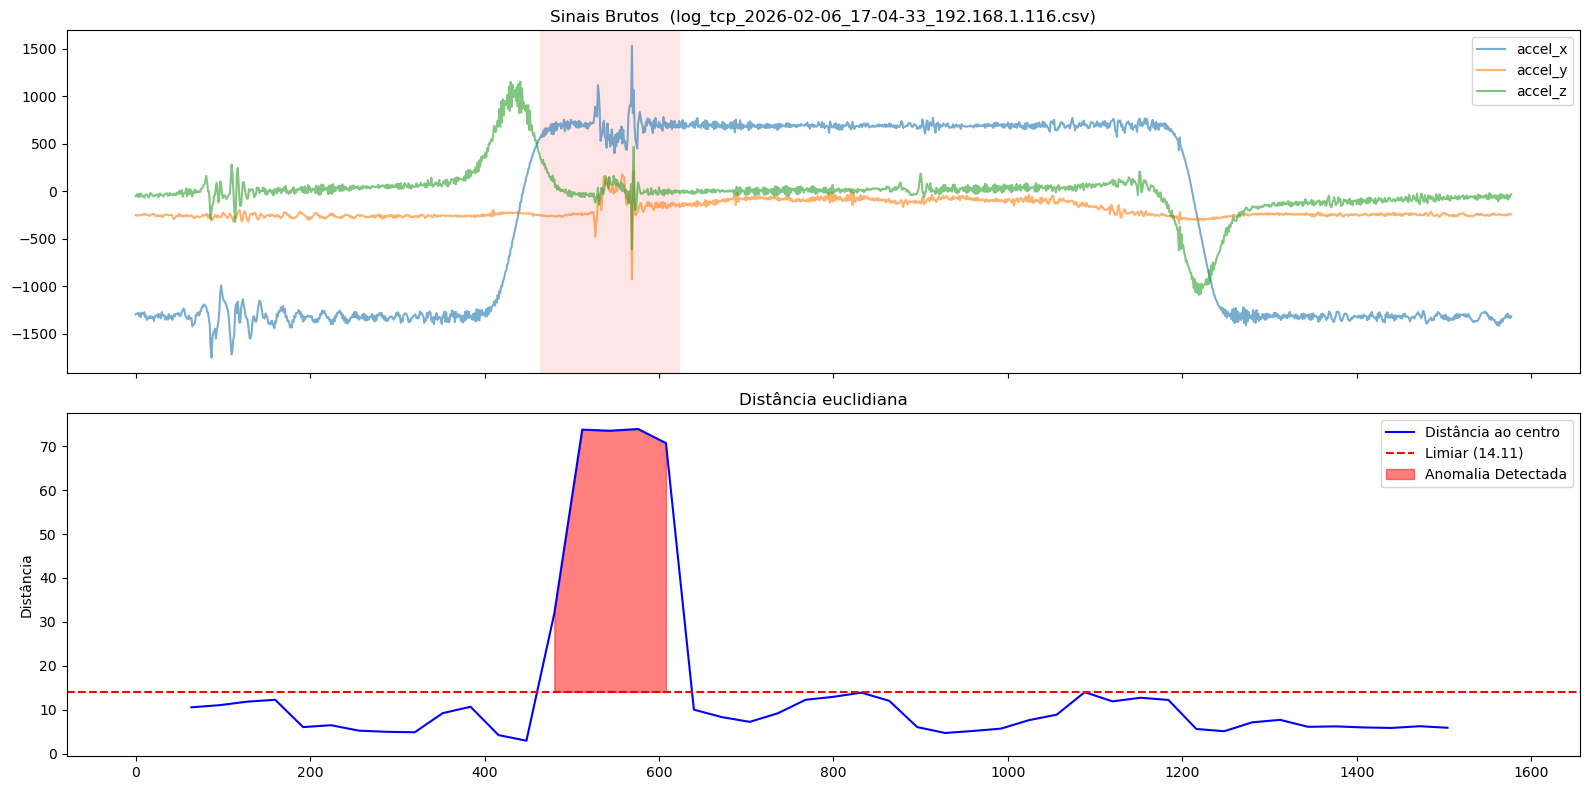

In [18]:
anomalia = '../arquivos/logs/logs_sensor_vale/logs_ext/an_curva_dir/*.csv'
lista = glob.glob(anomalia)
if lista:
    diagnostico_anomalia_kmeans(lista[1])

### CLuster anomalia

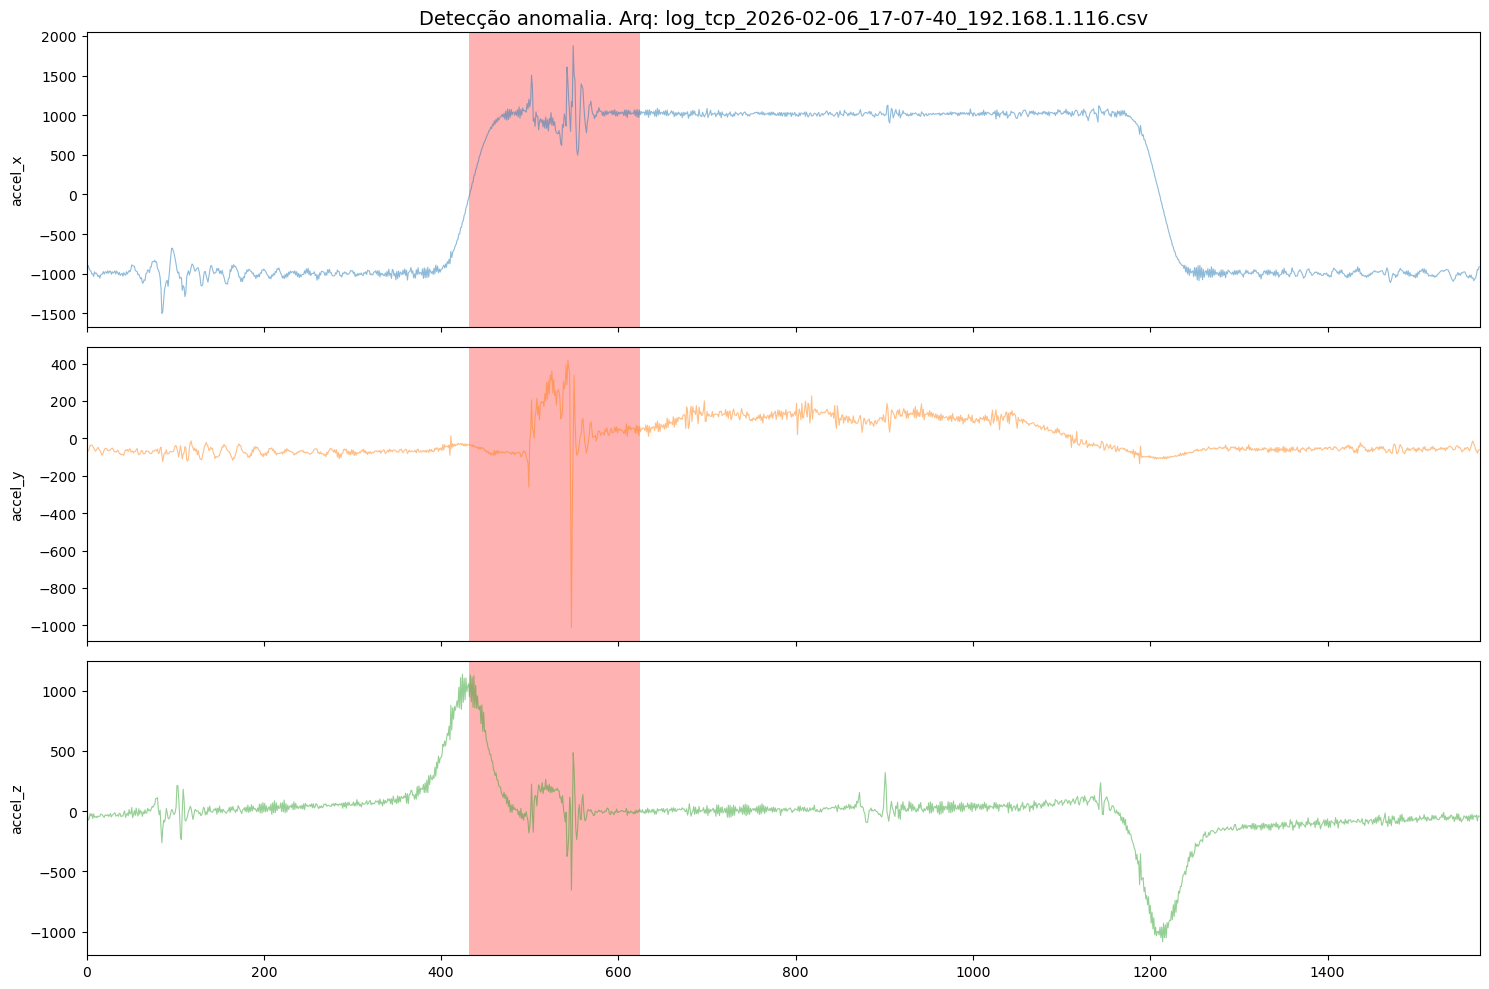

In [19]:
K_ANOMALIA = 4 
arquivos_anomalia = sorted(glob.glob(anomalia))

# n-1 treino, 1 teste
arquivos_treino_an = arquivos_anomalia[:-1]
arquivos_teste_an = arquivos_anomalia[-1:]
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_treino_an)

kmeans_an = KMeans(n_clusters=K_ANOMALIA, random_state=42, n_init=10)
kmeans_an.fit(X_pca)

meus_ids_anomalia = identificar_ids_anomalos(kmeans_an, kmeans_an_especifico)

for arq in arquivos_teste_an:
    visualizar_deteccao_confirmada(arq, kmeans, kmeans_an_especifico, meus_ids_anomalia)

## Anomalia entre roletes 1 e 2

### Distância até o centróide do cluster

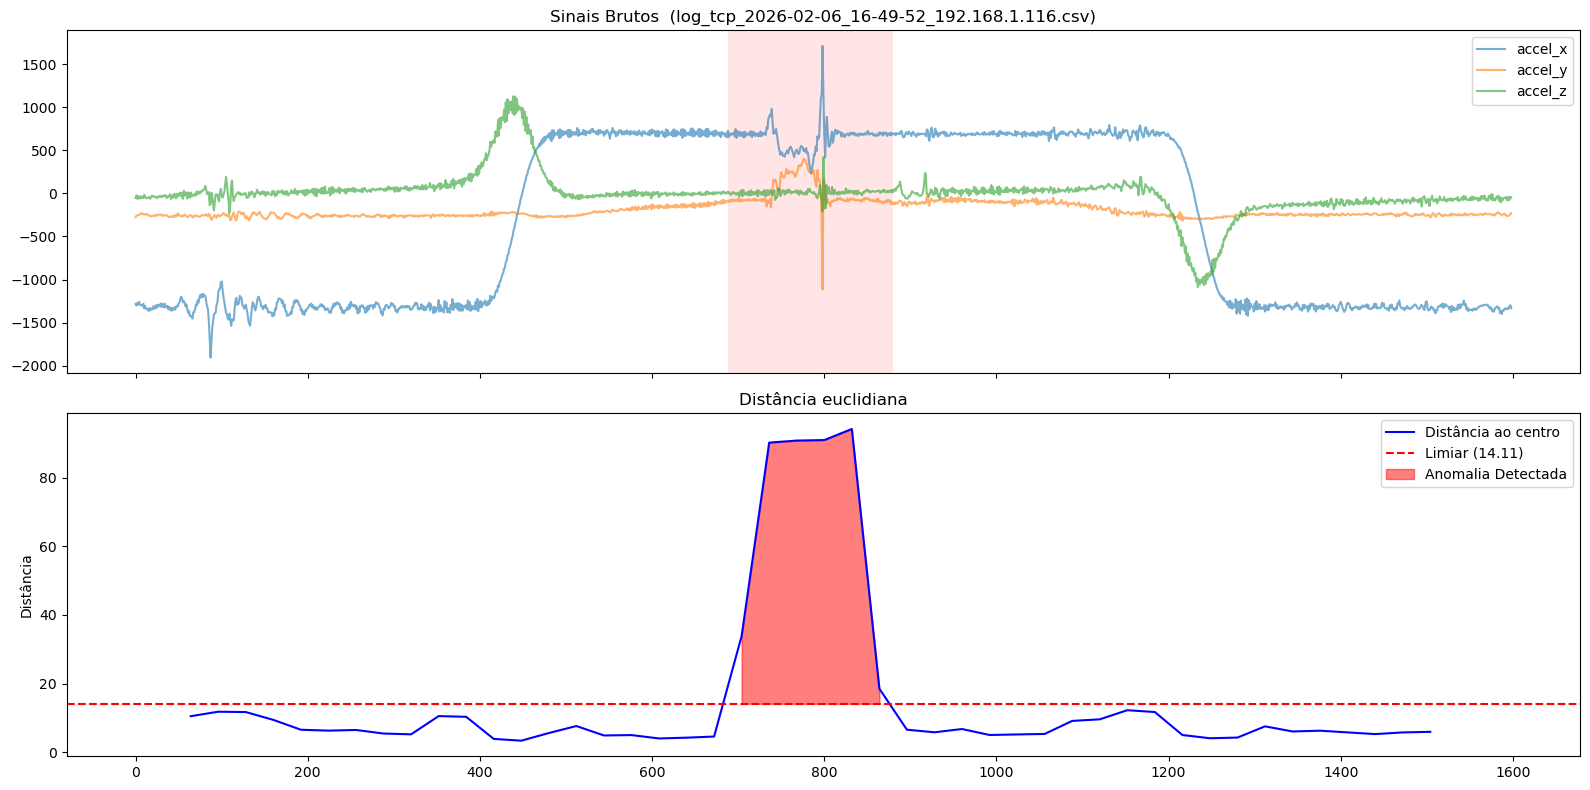

In [20]:
anomalia = '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_1_2/*.csv'
lista = glob.glob(anomalia)
if lista:
    diagnostico_anomalia_kmeans(lista[1])

### Cluster de anomalia

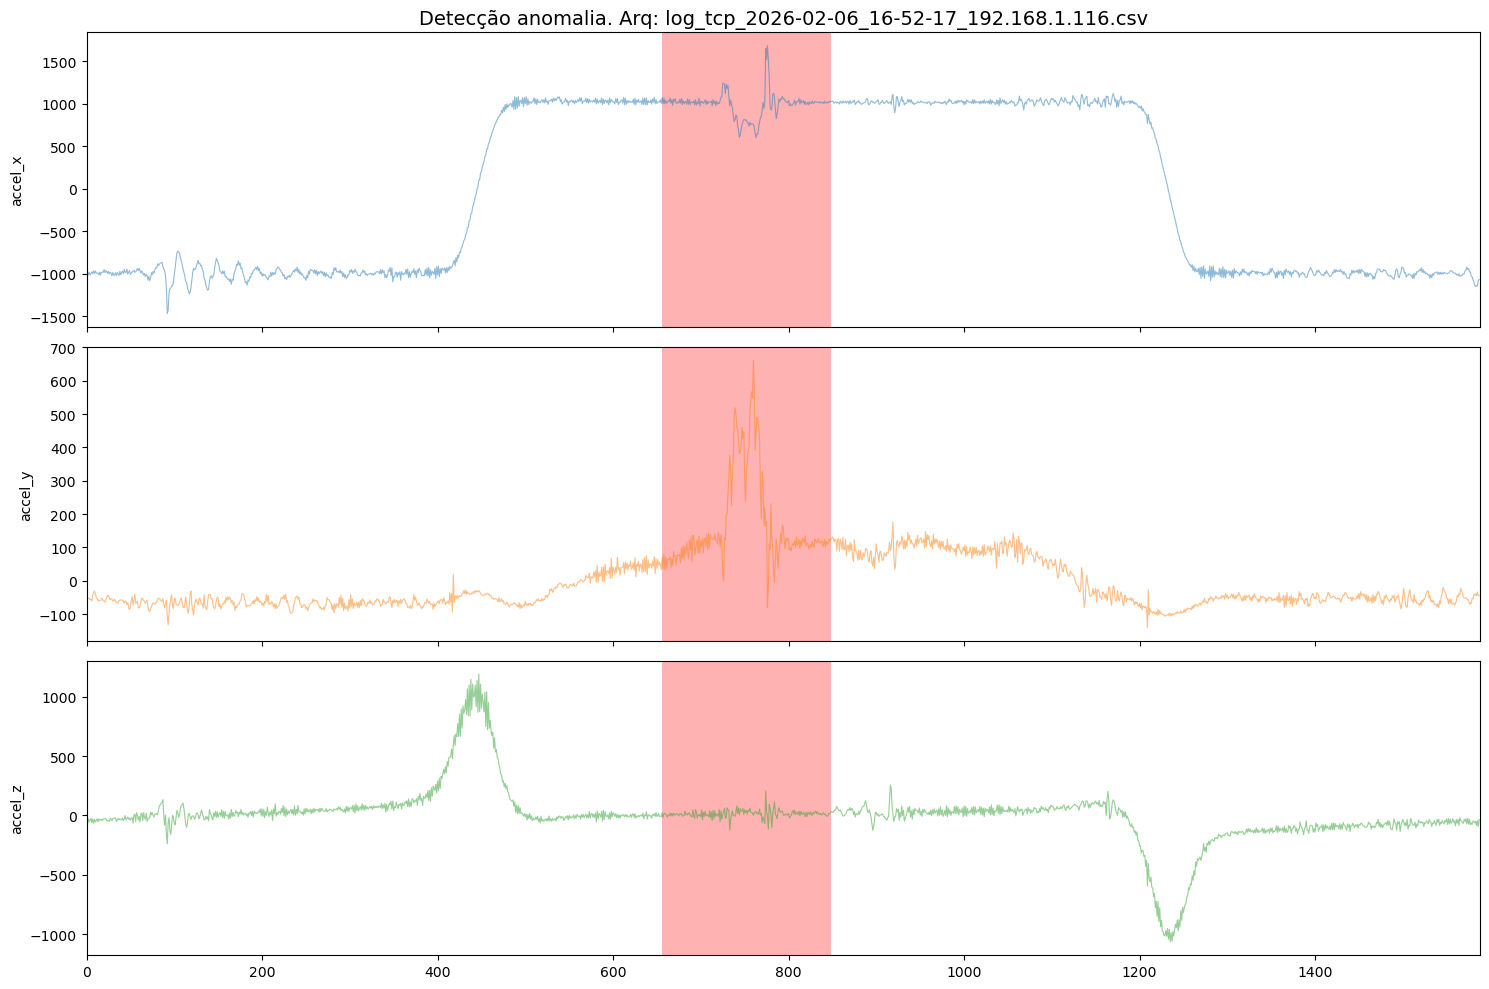

In [21]:
K_ANOMALIA = 4 
arquivos_anomalia = sorted(glob.glob(anomalia))

# n-1 treino, 1 teste
arquivos_treino_an = arquivos_anomalia[:-1]
arquivos_teste_an = arquivos_anomalia[-1:]
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_treino_an)

kmeans_an = KMeans(n_clusters=K_ANOMALIA, random_state=42, n_init=10)
kmeans_an.fit(X_pca)

meus_ids_anomalia = identificar_ids_anomalos(kmeans_an, kmeans_an_especifico)

for arq in arquivos_teste_an:
    visualizar_deteccao_confirmada(arq, kmeans, kmeans_an_especifico, meus_ids_anomalia)

## Anomalia entre roletes 2 e 3

### Distância até cenetróide do cluster

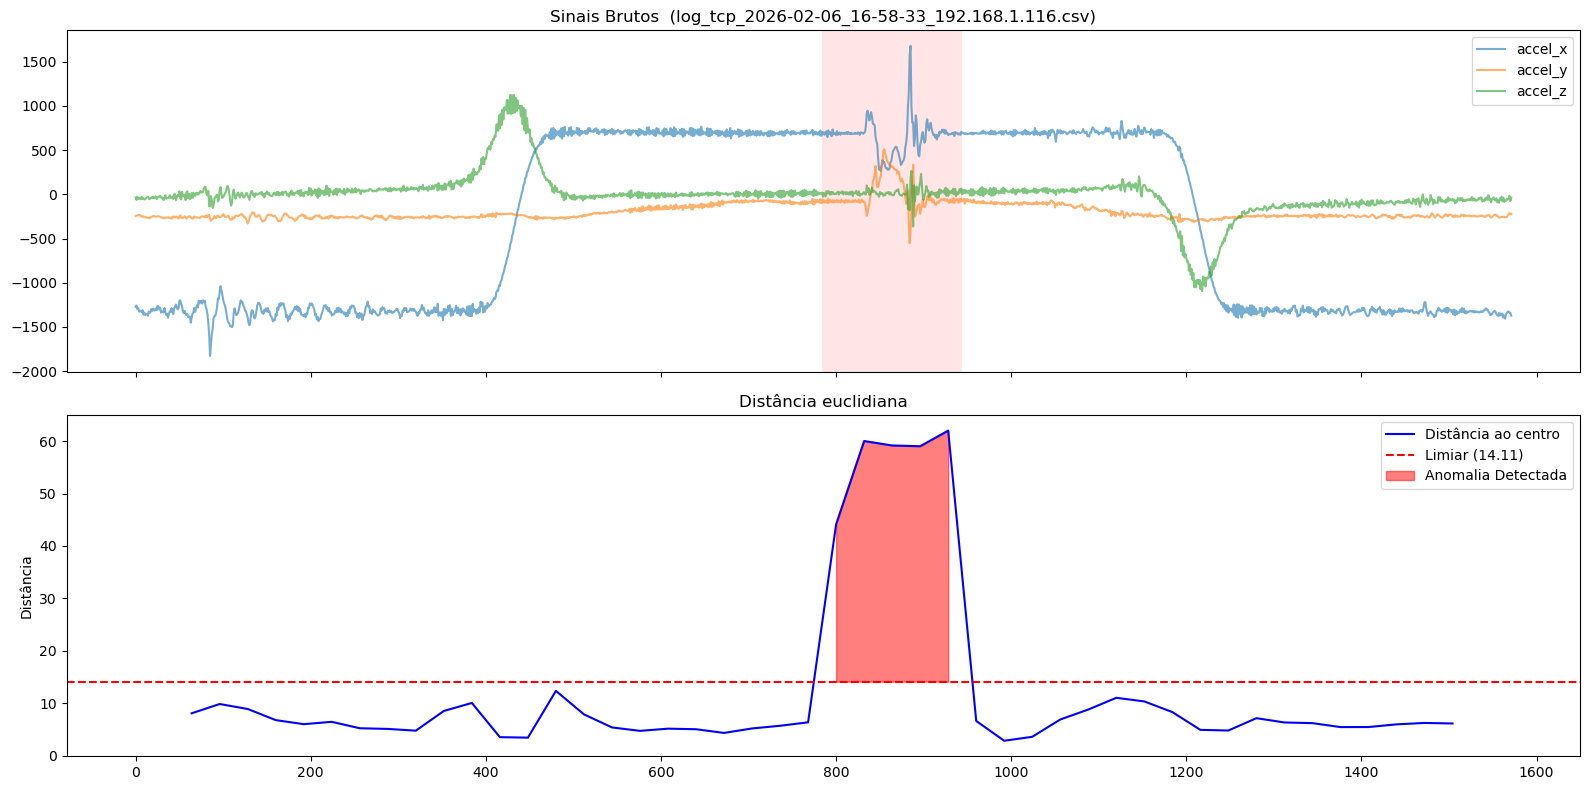

In [22]:
anomalia = '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_2_3/*.csv'
lista = glob.glob(anomalia)
if lista:
    diagnostico_anomalia_kmeans(lista[0])

### Cluster de anomalia

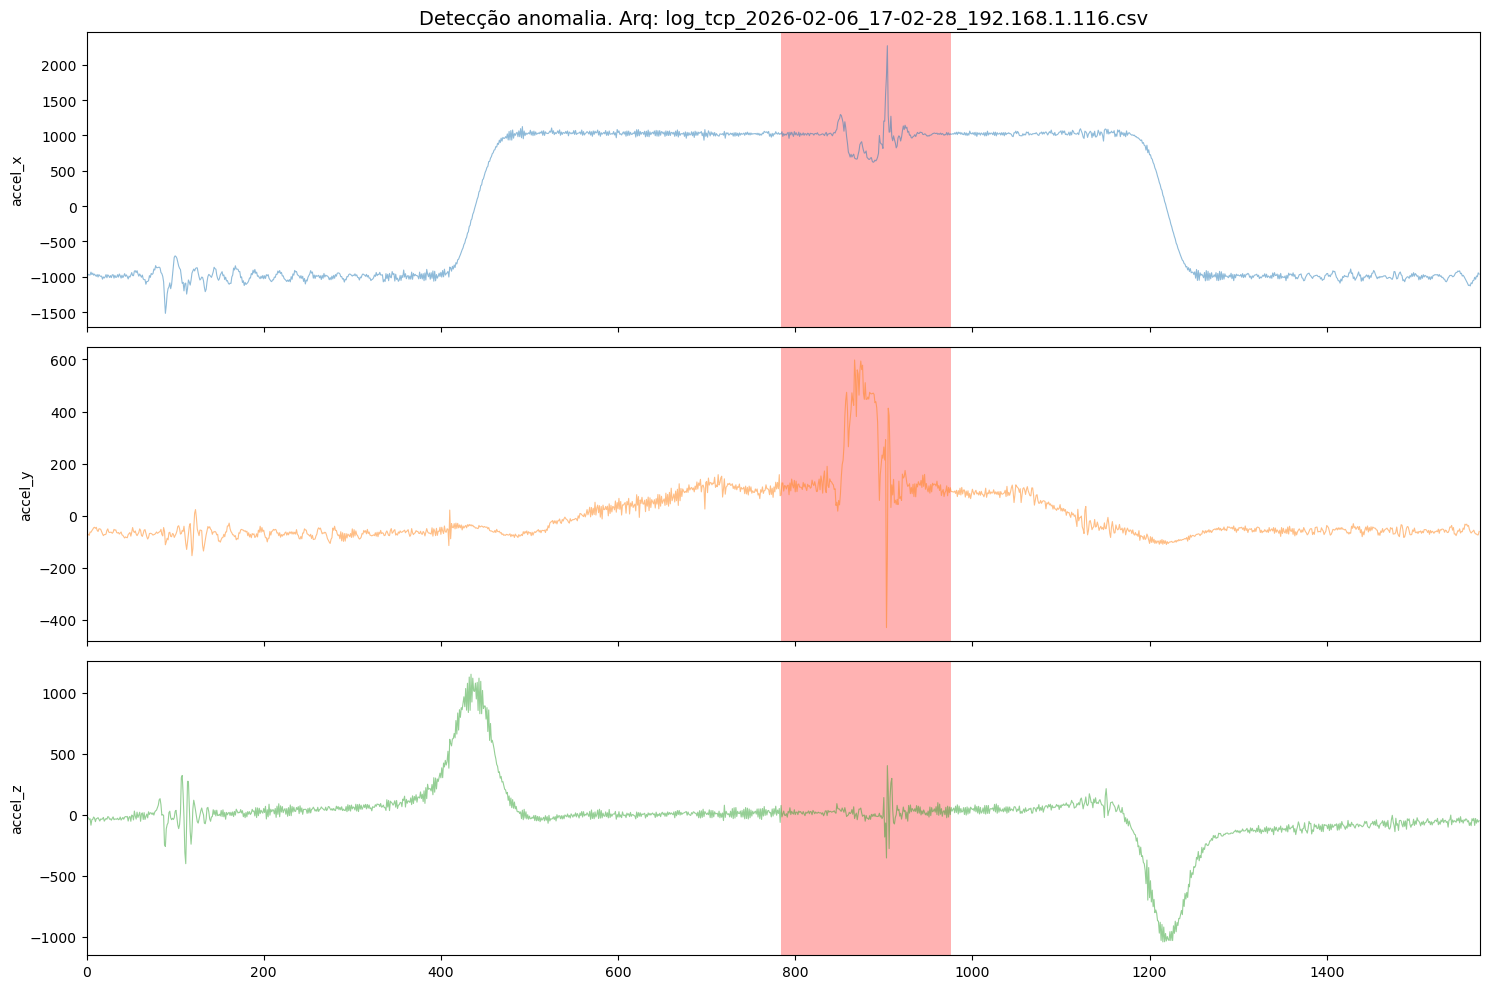

In [23]:
K_ANOMALIA = 4 
arquivos_anomalia = sorted(glob.glob(anomalia))

# n-1 treino, 1 teste
arquivos_treino_an = arquivos_anomalia[:-1]
arquivos_teste_an = arquivos_anomalia[-1:]
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_treino_an)

kmeans_an = KMeans(n_clusters=K_ANOMALIA, random_state=42, n_init=10)
kmeans_an.fit(X_pca)

meus_ids_anomalia = identificar_ids_anomalos(kmeans_an, kmeans_an_especifico)

for arq in arquivos_teste_an:
    visualizar_deteccao_confirmada(arq, kmeans, kmeans_an_especifico, meus_ids_anomalia)

## Anomalia entre roletes 3 e 4

### Distância até centróide do cluster

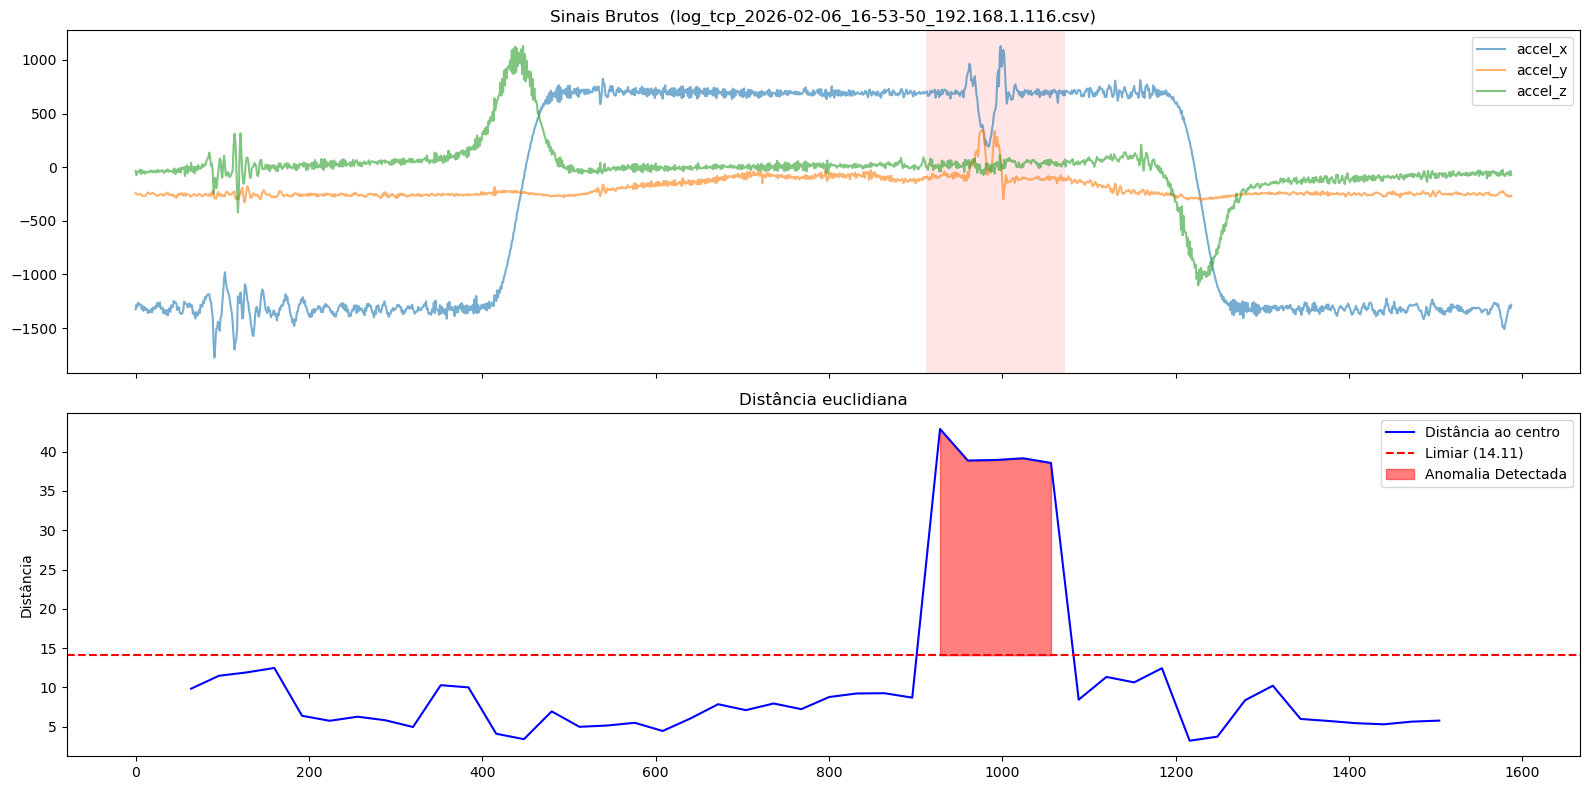

In [24]:
anomalia = '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_3_4/*.csv'
lista = glob.glob(anomalia)
if lista:
    diagnostico_anomalia_kmeans(lista[0])

### Cluster de anomalia

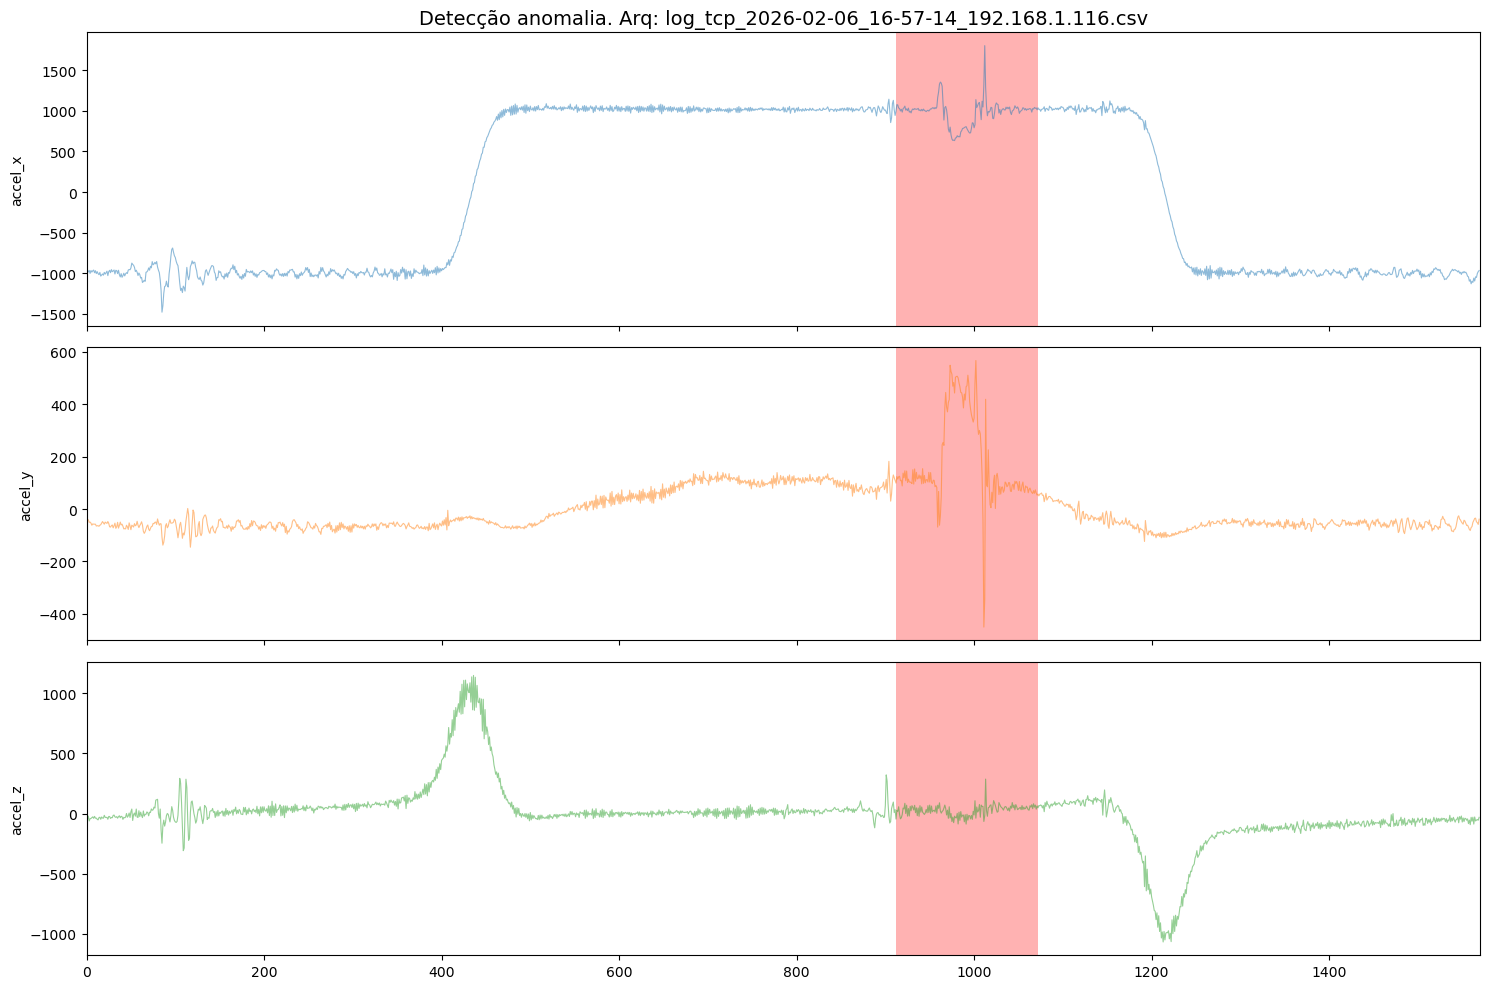

In [25]:
K_ANOMALIA = 4 
arquivos_anomalia = sorted(glob.glob(anomalia))

# n-1 treino, 1 teste
arquivos_treino_an = arquivos_anomalia[:-1]
arquivos_teste_an = arquivos_anomalia[-1:]
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_treino_an)

kmeans_an = KMeans(n_clusters=K_ANOMALIA, random_state=42, n_init=10)
kmeans_an.fit(X_pca)

meus_ids_anomalia = identificar_ids_anomalos(kmeans_an, kmeans_an_especifico)

for arq in arquivos_teste_an:
    visualizar_deteccao_confirmada(arq, kmeans, kmeans_an_especifico, meus_ids_anomalia)

# Validação dos modelos

In [ ]:
import glob
import numpy as np
from sklearn.model_selection import train_test_split

arquivos_treino_normal = sorted(glob.glob('../arquivos/logs/logs_sensor_vale/logs_ext/normal/*.csv'))
arquivos_teste_normal = sorted(glob.glob('../arquivos/logs/logs_sensor_vale/logs_ext/normal_v2/*.csv'))

pastas_anomalias = [
    '../arquivos/logs/logs_sensor_vale/logs_ext/an_curva_dir/*.csv',
    '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_1_2/*.csv',
    '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_2_3/*.csv',
    '../arquivos/logs/logs_sensor_vale/logs_ext/an_roletes_3_4/*.csv'
]

arquivos_treino_an_geral = []
arquivos_teste_an_geral = []

for pasta in pastas_anomalias:
    arquivos = sorted(glob.glob(pasta))
    # divide em teste/treino para CADA pasta de anomalia
    if len(arquivos) > 0:
        treino, teste = train_test_split(arquivos, test_size=0.2, random_state=42, shuffle=True)
        arquivos_treino_an_geral.extend(treino)
        arquivos_teste_an_geral.extend(teste)

print(f"Treino Normal: {len(arquivos_treino_normal)} arq")
print(f"Teste Normal (v2): {len(arquivos_teste_normal)} arq")
print(f"Treino Anomalias: {len(arquivos_treino_an_geral)} arq")
print(f"Teste Anomalias: {len(arquivos_teste_an_geral)} arq")

Treino Normal: 14 arq
Teste Normal (v2): 15 arq
Treino Anomalias: 42 arq
Teste Anomalias: 13 arq


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

todas_feats_normais = []
for arq in arquivos_treino_normal:
    feats, _, _ = processar_dataset_ml4qs(arq)
    if feats is not None:
        todas_feats_normais.append(feats)

X_normal = np.vstack(todas_feats_normais)

# Reajusta Scaler e PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_normal)
pca = PCA(n_components=6) # <---
X_pca_normal = pca.fit_transform(X_scaled)

# Treina K-Means original
K_NORMAL = 3
kmeans_orig = KMeans(n_clusters=K_NORMAL, random_state=42, n_init=10)
kmeans_orig.fit(X_pca_normal)

dists_treino_normal = kmeans_orig.transform(X_pca_normal)
distancia_minima_treino = np.min(dists_treino_normal, axis=1)
limiar_distancia = np.percentile(distancia_minima_treino, 99)
print(f"Limiar de distancia euclidiana: {limiar_distancia:.4f}")


K_ANOMALIA_GERAL = 12 

todas_feats_an = []
for arq in arquivos_treino_an_geral:
    feats, _, _ = processar_dataset_ml4qs(arq)
    if feats is not None:
        todas_feats_an.append(feats)

X_an_geral = np.vstack(todas_feats_an)
# Projeta os dados anômalos no mesmo espaço PCA dos normais
X_pca_an_geral = pca.transform(scaler.transform(X_an_geral))
kmeans_an_geral = KMeans(n_clusters=K_ANOMALIA_GERAL, random_state=42, n_init=10)
kmeans_an_geral.fit(X_pca_an_geral)
meus_ids_anomalia = identificar_ids_anomalos(kmeans_orig, kmeans_an_geral)
print(f"IDs de clusters classificados como anomalia: {meus_ids_anomalia}")

Limiar de distancia euclidiana: 13.7561
IDs de clusters classificados como anomalia: [1, 2, 6, 7, 8, 10]


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def calcular_predicoes_consenso(arquivos_normais, arquivos_anomalia, kmeans_normal, kmeans_an, ids_an, limiar, proporcao_minima=0.05):
    y_true_arquivo = []
    y_pred_dist_arquivo = []
    y_pred_clust_arquivo = []
    y_pred_inter_arquivo = []

    todos_arquivos = [(arq, 0) for arq in arquivos_normais] + [(arq, 1) for arq in arquivos_anomalia]

    for caminho_arquivo, rotulo_real in todos_arquivos:
        feats, indices, df = processar_dataset_ml4qs(caminho_arquivo)
        if feats is None or len(feats) == 0:
            continue
            
        f_pca = pca.transform(scaler.transform(feats))
        total_janelas = len(feats)

        # predições por janela
        dists_normais = kmeans_normal.transform(f_pca)
        esta_longe = np.min(dists_normais, axis=1) > limiar
        
        labels_an = kmeans_an.predict(f_pca)
        eh_cluster_anomalia = np.isin(labels_an, ids_an)
        
        confirmado = esta_longe & eh_cluster_anomalia

        # calcular proporção
        taxa_dist = np.sum(esta_longe) / total_janelas
        taxa_clust = np.sum(eh_cluster_anomalia) / total_janelas
        taxa_inter = np.sum(confirmado) / total_janelas

        y_true_arquivo.append(rotulo_real)
        y_pred_dist_arquivo.append(1 if taxa_dist >= proporcao_minima else 0)
        y_pred_clust_arquivo.append(1 if taxa_clust >= proporcao_minima else 0)
        y_pred_inter_arquivo.append(1 if taxa_inter >= proporcao_minima else 0)

    return y_true_arquivo, y_pred_dist_arquivo, y_pred_clust_arquivo, y_pred_inter_arquivo

y_true, y_dist, y_clust, y_inter = calcular_predicoes_consenso(
    arquivos_normais=arquivos_teste_normal, 
    arquivos_anomalia=arquivos_teste_an_geral, 
    kmeans_normal=kmeans_orig, 
    kmeans_an=kmeans_an_geral, 
    ids_an=meus_ids_anomalia, 
    limiar=limiar_distancia,
    proporcao_minima=0.05 # <---
)

metodos = ['Distância Euclidiana', 'Cluster de Anomalia']
predicoes = [y_dist, y_clust, y_inter]

print(f"{'Método':<30} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 68)


matrizes_confusao = []
for nome_metodo, y_pred in zip(metodos, predicoes):
    precisao = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    print(f"{nome_metodo:<30} | {precisao:<10.4f} | {recall:<10.4f} | {f1:<10.4f}")
    
    cm = confusion_matrix(y_true, y_pred)
    matrizes_confusao.append((nome_metodo, cm))

Método                         | Precision  | Recall     | F1-Score  
--------------------------------------------------------------------
Distância Euclidiana           | 1.0000     | 1.0000     | 1.0000    
Cluster de Anomalia            | 1.0000     | 1.0000     | 1.0000    


In [29]:
for nome_metodo, cm in matrizes_confusao:
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
    else:
        tn = fp = fn = tp = "?" 
        
    print(f"\n{nome_metodo}")
    print(f"              | Previsto Normal     | Previsto Anomalia")
    print(f"--------------|---------------------|-----------------")
    print(f"Real Normal   | {str(tn):<19} | {str(fp):<20}")
    print(f"Real Anomalia | {str(fn):<19} | {str(tp):<20}")


Distância Euclidiana
              | Previsto Normal     | Previsto Anomalia
--------------|---------------------|-----------------
Real Normal   | 15                  | 0                   
Real Anomalia | 0                   | 13                  

Cluster de Anomalia
              | Previsto Normal     | Previsto Anomalia
--------------|---------------------|-----------------
Real Normal   | 15                  | 0                   
Real Anomalia | 0                   | 13                  
